In [1]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    "/Users/abhishekbanajawad/Desktop/ML_projects/Log_Regression_churn_1"
)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank_churn.csv"

bank_raw = pd.read_csv(DATA_PATH)

print("Dataset shape:", bank_raw.shape)
print("\nColumn names:")
print(bank_raw.columns.tolist())

display(bank_raw.head())

Dataset shape: (10000, 12)

Column names:
['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [2]:
bank_raw.info()

quality_summary = pd.DataFrame({
    'dtype': bank_raw.dtypes,
    'missing_count': bank_raw.isnull().sum(),
    'unique_count': bank_raw.nunique(),
})

display(quality_summary)

print("Duplicate complete rows:",
      bank_raw.duplicated().sum())

print("Repeated customer ID:", 
      bank_raw['customer_id'].duplicated().sum())

print("Duplicate excluding customer ID:",
      bank_raw.drop(columns=['customer_id']).duplicated().sum())

for col in ['credit_card', 'active_member', 'churn']:
    print(f"{col}: {bank_raw[col].unique()}")

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 1.0 MB


,dtype,missing_count,unique_count
customer_id,int64,0,10000
credit_score,int64,0,460
country,str,0,3
gender,str,0,2
age,int64,0,70
tenure,int64,0,11
balance,float64,0,6382
products_number,int64,0,4
credit_card,int64,0,2
active_member,int64,0,2


Duplicate complete rows: 0
Repeated customer ID: 0
Duplicate excluding customer ID: 0
credit_card: [1 0]
active_member: [1 0]
churn: [1 0]


In [3]:
print("Churned counts:", (bank_raw['churn'] == 1).sum())
print("Non-churned counts:", (bank_raw['churn'] == 0).sum())

Churned counts: 2037
Non-churned counts: 7963


In [4]:
from sklearn.model_selection import train_test_split

# 60% train, 20% validation, 20% test
# 20% test data
development_data, test_data = train_test_split(
    bank_raw,
    test_size = 0.2,
    random_state = 42,
    shuffle = True,
    stratify = bank_raw['churn'],
)

# 20% val data
train_data, val_data = train_test_split(
    development_data,
    test_size = 0.25,
    random_state = 42,
    shuffle = True,
    stratify = development_data['churn'],
)

train_data = train_data.copy()
val_data = val_data.copy()
test_data = test_data.copy()


print('Training shape:', train_data.shape)
print('Validation shape:', val_data.shape)
print('Test shape:', test_data.shape)



Training shape: (6000, 12)
Validation shape: (2000, 12)
Test shape: (2000, 12)


In [5]:
train_ids = set(train_data["customer_id"])
val_ids = set(val_data["customer_id"])
test_ids = set(test_data["customer_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert (
    len(train_data) + len(val_data) + len(test_data)
    == len(bank_raw)
)

print("Checks passed: no customer overlap and all rows accounted for.")

Checks passed: no customer overlap and all rows accounted for.


In [6]:
class_summary = (
    train_data["churn"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

class_summary["percentage"] = (
    class_summary["customer_count"] / len(train_data) * 100
).round(2)

display(class_summary)


,customer_count,percentage
churn,,
0,4777,79.62
1,1223,20.38


In [7]:
numeric_features = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'products_number',
    'estimated_salary'
]

display(
    train_data[numeric_features].describe().T
)

for col in ['country', 'gender']:
    print(f"\n{col}:")
    display(
        train_data[col].value_counts(dropna = False)
    )

,count,mean,std,min,25%,50%,75%,max
credit_score,6000.0,651.102500,96.645467,350.00,584.0000,652.000,717.0000,850.00
age,6000.0,38.959667,10.482144,18.00,32.0000,37.000,44.0000,92.00
tenure,6000.0,5.027833,2.907943,0.00,3.0000,5.000,8.0000,10.00
balance,6000.0,77261.098155,62284.911851,0.00,0.0000,97757.240,128293.9500,238387.56
products_number,6000.0,1.533833,0.584733,1.00,1.0000,1.000,2.0000,4.00
estimated_salary,6000.0,99452.181700,57283.092853,90.07,50691.8175,99107.435,147891.1525,199992.48



country:


country
France     2980
Spain      1516
Germany    1504
Name: count, dtype: int64


gender:


gender
Male      3276
Female    2724
Name: count, dtype: int64

In [8]:
category_features = [
    'country',
    'gender',
    'products_number',
    'credit_card',
    'active_member'
]

for col in category_features:
    summary = (
        train_data.groupby(col)['churn']
        .agg(
            customer = 'size',
            churned_customers = 'sum',
            churn_rate = 'mean',
        )
    )

    summary['churn_rate_pct'] = (
        summary['churn_rate'] * 100
    ).round(2)

    display(
        summary[
            ['customer', 'churned_customers', 'churn_rate_pct']
            ]
    )

,customer,churned_customers,churn_rate_pct
country,,,
France,2980,487,16.34
Germany,1504,489,32.51
Spain,1516,247,16.29


,customer,churned_customers,churn_rate_pct
gender,,,
Female,2724,693,25.44
Male,3276,530,16.18


,customer,churned_customers,churn_rate_pct
products_number,,,
1,3037,846,27.86
2,2762,202,7.31
3,162,136,83.95
4,39,39,100.00


,customer,churned_customers,churn_rate_pct
credit_card,,,
0,1742,378,21.70
1,4258,845,19.84


,customer,churned_customers,churn_rate_pct
active_member,,,
0,2907,785,27.00
1,3093,438,14.16


In [9]:

numeric_comparsion = (
    train_data
    .groupby('churn')[numeric_features]
    .agg(['mean', 'median'])
    .T
)

numeric_comparsion.columns = [
    'retained_0', 'churned_1'
]
display(numeric_comparsion.round(2))

retained_0  churned_1
credit_score     mean        652.25     646.63
                 median      654.00     646.00
age              mean         37.49      44.71
                 median       36.00      45.00
tenure           mean          5.04       4.98
                 median        5.00       5.00
balance          mean      73208.68   93089.71
                 median    92636.96  110240.04
products_number  mean          1.55       1.48
                 median        2.00       1.00
estimated_salary mean      98627.30  102674.15
                 median    97658.66  104678.78

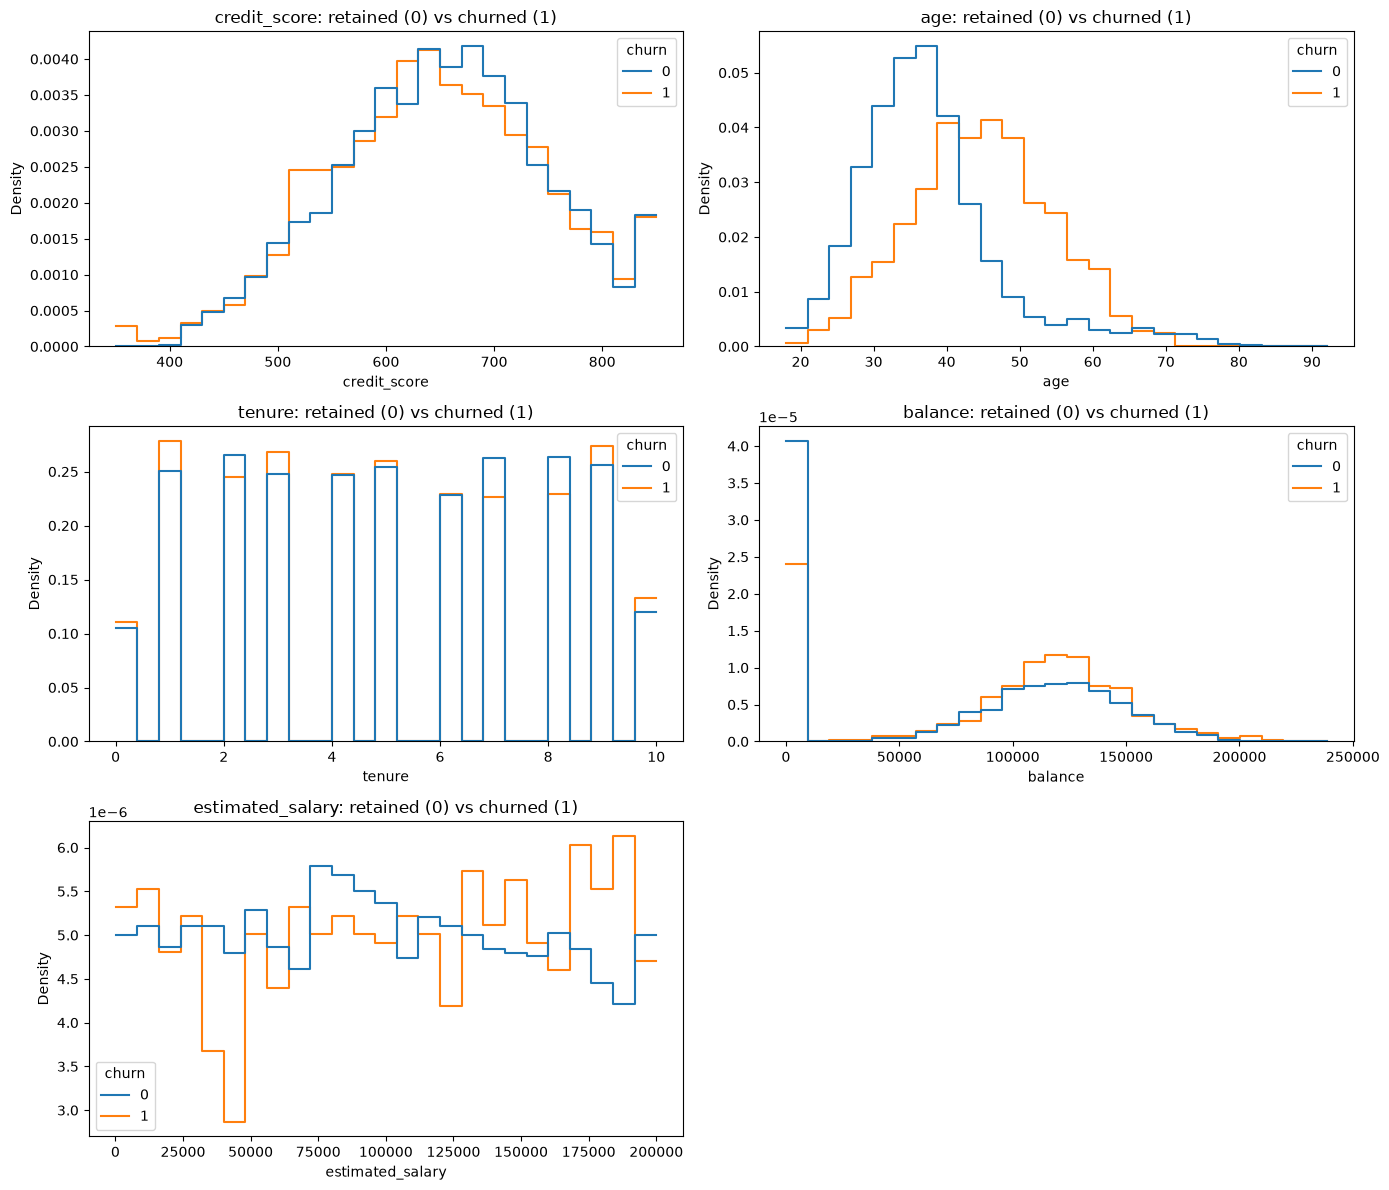

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# product count is discrete, so we will examine it separately.

distribution_features = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'estimated_salary'
]

fig, axes = plt.subplots(
    nrows = 3,
    ncols = 2,
    figsize = (14, 12),
)

for ax, feature in zip(axes.flat, distribution_features):
    sns.histplot(
        data = train_data,
        x = feature,
        hue = 'churn',
        stat = 'density',
        common_norm = False,
        common_bins = True,
        bins = 25,
        element = 'step',
        fill = False,
        ax = ax
    )

    ax.set_title(f"{feature}: retained (0) vs churned (1)")
    ax.set_ylabel('Density')

# Hide the unused sixth panel
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [11]:
# Create a temporary indicator without changing train_data.

balance_analysis = train_data.assign(
    zero_balance = train_data['balance'].eq(0)
)

balance_summary = (
    balance_analysis.groupby('zero_balance')['churn']
    .agg(
        customers = 'size',
        churned_customers = 'sum',
        churn_rate = 'mean'
    )
)

balance_summary['churn_rate_pct'] = (
    balance_summary['churn_rate'] * 100
).round(2)

display(
    balance_summary[
        ['customers', 'churned_customers', 'churn_rate_pct']
    ]
)

,customers,churned_customers,churn_rate_pct
zero_balance,,,
False,3869,943,24.37
True,2131,280,13.14


In [12]:
age_analysis = train_data.assign(
    age_group = pd.cut(
        train_data['age'],
        bins = [0, 30, 40, 50, 60, float('inf')],
        labels = ['under 30', '30-39', '40-49', '50-59', '60+'],
        right = False
    )
)

age_summary = (
    age_analysis.groupby('age_group', observed = True)['churn']
    .agg(
        customers = 'size',
        churned_customers = 'sum',
        churn_rate = 'mean'
    )
)

age_summary['churn_rate_pct'] = (
    age_summary['churn_rate'] * 100
).round(2)

display(
    age_summary[
        ['customers', 'churned_customers', 'churn_rate_pct']
    ]
)

,customers,churned_customers,churn_rate_pct
age_group,,,
under 30,971,78,8.03
30-39,2641,286,10.83
40-49,1544,479,31.02
50-59,528,290,54.92
60+,316,90,28.48


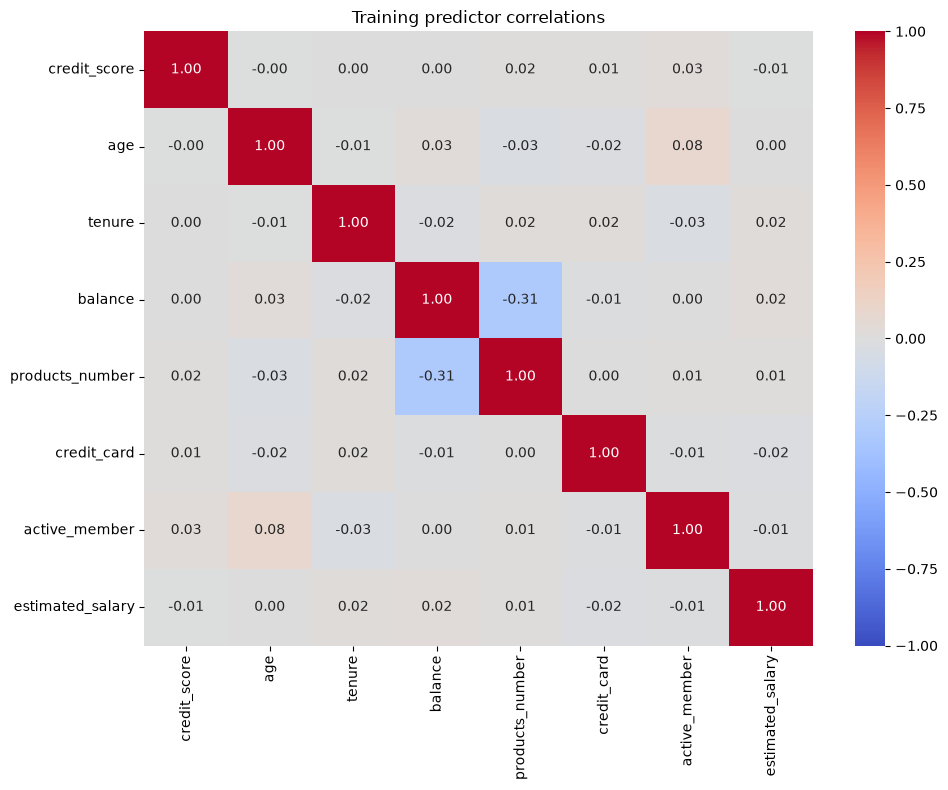

In [13]:
# Correlation between numeric predictors
correlation_features = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'products_number',
    'credit_card',
    'active_member',
    'estimated_salary'
]

correlation_matrix = train_data[correlation_features].corr()

plt.figure(figsize = (10, 8))

sns.heatmap(
    correlation_matrix,
    annot = True,
    fmt = '.2f',
    cmap = 'coolwarm',
    center = 0,
    vmin = -1,
    vmax = 1)
plt.title('Training predictor correlations')
plt.tight_layout()
plt.show()

In [14]:
# Separate identifiers and target from model inputs.
feature_columns = [
    column
    for column in train_data.columns
    if column not in ['customer_id', 'churn']
]

X_train = train_data[feature_columns].copy()
y_train = train_data['churn'].copy()

X_val = val_data[feature_columns].copy()
y_val = val_data['churn'].copy()

print('Training features shape:', X_train.shape)
print('Training target shape:', y_train.shape)

print('Validation features shape:', X_val.shape)
print('Validation target shape:', y_val.shape)

Training features shape: (6000, 10)
Training target shape: (6000,)
Validation features shape: (2000, 10)
Validation target shape: (2000,)


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

#learn which class is more frequent in training data
dummy_model = DummyClassifier(strategy = 'most_frequent')
dummy_model.fit(X_train, y_train)

# predict labels for validation customers
dummy_predictions = dummy_model.predict(X_val)

dummy_metrics = pd.Series({
    'accuracy': accuracy_score(y_val, dummy_predictions),
    'precision': precision_score(
        y_val, dummy_predictions, zero_division = 0
    ),
    'recall': recall_score(y_val, dummy_predictions),
    'f1': f1_score(y_val, dummy_predictions)
})

display(dummy_metrics.round(4))

print('confusion matrix:')
print(
    confusion_matrix(
        y_val,
        dummy_predictions,
        labels = [0, 1]
    )
)

accuracy     0.7965
precision    0.0000
recall       0.0000
f1           0.0000
dtype: float64

confusion matrix:
[[1593    0]
 [ 407    0]]


In [16]:
numeric_features = [
    'credit_score',
    'age',
    'tenure',
    'balance',
    'products_number',
    'estimated_salary'
]

categorical_features = [
    'country',
    'gender'
]

binary_features = [
    'credit_card',
    'active_member'
]

# Confirm that every predictor belongs to exactly one group
all_features = (
    numeric_features
    + categorical_features
    + binary_features
)

assert len(all_features) == len(set(all_features))
assert set(all_features) == set(X_train.columns)

print('Feature groups verified')

Feature groups verified


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers = [
        ('numeric', StandardScaler(), numeric_features),
        (
            'categorical', 
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features,
        ),
        ('binary', 'passthrough', binary_features),
    ],
    remainder = 'drop',
)

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps = [
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter = 1000))
    ]
)

logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['credit_score','country','gender',...,'credit_card','active_member', 'estimated_salary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

In [19]:
# Predicted labels: 0 or 1
logistic_predictions = logistic_pipeline.predict(X_val)

# predicted probability of churn
logistic_probabilities = logistic_pipeline.predict_proba(X_val)[:, 1]

print('First 10 predicted labels:')
print(logistic_predictions[:10])

print('\nFirst 10 churn probabilities:')
print(logistic_predictions[:10].round(3))

First 10 predicted labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 churn probabilities:
[0 0 0 0 0 0 0 0 0 0]


In [20]:
# Check which model is inside the pipeline.
print(logistic_pipeline.named_steps["model"])

# Obtain probabilities directly, without rounding or conversion.
probability_matrix = logistic_pipeline.predict_proba(X_val)

print("\nClass order:", logistic_pipeline.classes_)
print("Probability data type:", probability_matrix.dtype)

print("\nFirst 10 probability rows:")
print(probability_matrix[:10])

logistic_probabilities = probability_matrix[:, 1]

print("\nMinimum churn probability:", logistic_probabilities.min())
print("Maximum churn probability:", logistic_probabilities.max())

LogisticRegression(max_iter=1000)

Class order: [0 1]
Probability data type: float64

First 10 probability rows:
[[0.94476412 0.05523588]
 [0.92993379 0.07006621]
 [0.60389184 0.39610816]
 [0.84083864 0.15916136]
 [0.9379339  0.0620661 ]
 [0.8826673  0.1173327 ]
 [0.80966739 0.19033261]
 [0.93542205 0.06457795]
 [0.95614165 0.04385835]
 [0.69189169 0.30810831]]

Minimum churn probability: 0.011386027174305733
Maximum churn probability: 0.9265074805101435


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

logistic_predictions = logistic_pipeline.predict(X_val)

logistic_probabilities = logistic_pipeline.predict_proba(
    X_val
)[:, 1]

logistic_metrics = pd.Series({
    "accuracy": accuracy_score(y_val, logistic_predictions),
    "precision": precision_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "recall": recall_score(y_val, logistic_predictions),
    "f1": f1_score(y_val, logistic_predictions),
    "roc_auc": roc_auc_score(y_val, logistic_probabilities),
    "average_precision": average_precision_score(
        y_val, logistic_probabilities
    ),
})

display(logistic_metrics.round(4))

print("Confusion matrix:")
print(confusion_matrix(
    y_val,
    logistic_predictions,
    labels=[0, 1],
))

accuracy             0.8090
precision            0.5839
recall               0.2138
f1                   0.3129
roc_auc              0.7568
average_precision    0.4630
dtype: float64

Confusion matrix:
[[1531   62]
 [ 320   87]]


In [22]:
fitted_model = logistic_pipeline.named_steps["model"]

print("Solver iterations:", fitted_model.n_iter_)
print("Maximum allowed:", fitted_model.max_iter)

Solver iterations: [12]
Maximum allowed: 1000


In [25]:
import mlflow

#use an absolute path so tracking works from notebook folder
tracking_uri = f"sqlite:///{(PROJECT_ROOT / "mlflow.db").as_posix()}"

mlflow.set_tracking_uri(tracking_uri)

experiment_name = "bank-churn-model-comparison"
artifact_folder = PROJECT_ROOT / "mlflow_artifacts"

# create the experiment only if it doesn't already exist
if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(
        name = experiment_name,
        artifact_location = artifact_folder.as_uri(),
    )

mlflow.set_experiment(experiment_name)

print("Tracking location:", mlflow.get_tracking_uri())


Tracking location: sqlite:////Users/abhishekbanajawad/Desktop/ML_projects/Log_Regression_churn_1/mlflow.db


In [27]:
with mlflow.start_run(
    run_name="logistic-original-features-default-threshold"
) as run:

    # Record the actual model configuration.
    mlflow.log_params(
        logistic_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "training_rows": len(X_train),
        "validation_rows": len(X_val),
        "split_random_state": 42,
        "decision_threshold": 0.5,
        "feature_set": "original_10_predictors",
        "numeric_scaling": "StandardScaler",
        "categorical_encoding": "OneHotEncoder",
    })

    # Prefix names to identify the evaluation partition.
    mlflow.log_metrics({
        f"validation_{name}": float(value)
        for name, value in logistic_metrics.items()
    })

    # Save supporting information as artifacts.
    mlflow.log_dict(
        {"predictors": X_train.columns.tolist()},
        "features.json",
    )

    mlflow.log_dict(
        {
            "labels": [0, 1],
            "rows": "actual",
            "columns": "predicted",
            "matrix": confusion_matrix(
                y_val,
                logistic_predictions,
                labels=[0, 1],
            ).tolist(),
        },
        "validation_confusion_matrix.json",
    )

    mlflow.set_tags({
        "stage": "initial_baseline",
        "evaluation": "validation",
        "test_set_used": "false",
    })

    print("Saved run ID:", run.info.run_id)

Saved run ID: 763f10362aa3464b94b6980574e2950e


In [28]:
import mlflow.sklearn
from mlflow.models import infer_signature

# Identify the run created by our earlier logging cell.
baseline_run_id = run.info.run_id

print("Updating run:", baseline_run_id)

# Describe the expected input columns and prediction output.
signature = infer_signature(
    X_train,
    logistic_pipeline.predict(X_train),
)

# Reopen the existing run and save the fitted pipeline.
with mlflow.start_run(run_id=baseline_run_id):
    model_info = mlflow.sklearn.log_model(
        sk_model=logistic_pipeline,
        name="logistic_pipeline",
        signature=signature,
    )

print("Saved model URI:", model_info.model_uri)

Updating run: 763f10362aa3464b94b6980574e2950e


/Users/abhishekbanajawad/Desktop/ML_projects/Log_Regression_churn_1/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Saved model URI: models:/m-3dbfaf2ac6c340d3a3dc696280812f68


In [30]:
import numpy as np

loaded_pipeline = mlflow.sklearn.load_model(
    model_info.model_uri
)

original_probabilities = logistic_pipeline.predict_proba(X_val)
loaded_probabilities = loaded_pipeline.predict_proba(X_val)

np.testing.assert_allclose(
    original_probabilities,
    loaded_probabilities,
)

print("Verified: the saved pipeline reproduces the original probabilities.")

Verified: the saved pipeline reproduces the original probabilities.


In [32]:
import hashlib
import platform
import subprocess
import sys
import tempfile
from pathlib import Path

# Fingerprint the exact CSV bytes used in this project.
dataset_sha256 = hashlib.sha256(
    DATA_PATH.read_bytes()
).hexdigest()

# Capture packages from the notebook's Python environment.
requirements_text = subprocess.check_output(
    [sys.executable, "-m", "pip", "freeze"],
    text=True,
)

with tempfile.TemporaryDirectory() as temporary_directory:
    artifact_path = Path(temporary_directory)

    # Record customer membership without storing test outcomes.
    split_membership = pd.concat(
        [
            train_data[["customer_id"]].assign(split="train"),
            val_data[["customer_id"]].assign(split="validation"),
            test_data[["customer_id"]].assign(split="test"),
        ],
        ignore_index=True,
    )

    split_membership.to_csv(
        artifact_path / "split_membership.csv",
        index=False,
    )

    (artifact_path / "requirements.txt").write_text(
        requirements_text,
        encoding="utf-8",
    )

    with mlflow.start_run(run_id=baseline_run_id):
        mlflow.log_dict(
            {
                "filename": DATA_PATH.name,
                "sha256": dataset_sha256,
                "rows": len(bank_raw),
                "columns": bank_raw.columns.tolist(),
                "source": (
                    "https://www.kaggle.com/datasets/"
                    "gauravtopre/bank-customer-churn-dataset"
                ),
                "split_method": "two-stage stratified random split",
                "first_holdout_fraction": 0.20,
                "second_holdout_fraction_of_remaining": 0.25,
                "random_state": 42,
                "python_version": platform.python_version(),
            },
            "reproducibility/dataset_and_split.json",
        )

        mlflow.log_artifacts(
            str(artifact_path),
            artifact_path="reproducibility",
        )

print("Data, split membership, and environment details recorded.")

Data, split membership, and environment details recorded.


In [36]:
# Recalculate predictions from the fitted dummy model.
dummy_predictions = dummy_model.predict(X_val)
dummy_probabilities = dummy_model.predict_proba(X_val)[:, 1]

dummy_metrics = {
    "validation_accuracy": accuracy_score(
        y_val, dummy_predictions
    ),
    "validation_precision": precision_score(
        y_val, dummy_predictions, zero_division=0
    ),
    "validation_recall": recall_score(
        y_val, dummy_predictions
    ),
    "validation_f1": f1_score(
        y_val, dummy_predictions
    ),
    "validation_roc_auc": roc_auc_score(
        y_val, dummy_probabilities
    ),
    "validation_average_precision": average_precision_score(
        y_val, dummy_probabilities
    ),
}

with mlflow.start_run(run_name="dummy-most-frequent") as dummy_run:
    mlflow.log_params({
        "strategy": dummy_model.strategy,
        "training_rows": len(X_train),
        "validation_rows": len(X_val),
        "split_random_state": 42,
    })

    mlflow.log_metrics(dummy_metrics)

    mlflow.log_dict(
        {
            "labels": [0, 1],
            "rows": "actual",
            "columns": "predicted",
            "matrix": confusion_matrix(
                y_val,
                dummy_predictions,
                labels=[0, 1],
            ).tolist(),
        },
        "validation_confusion_matrix.json",
    )

    mlflow.set_tags({
        "stage": "dummy_baseline",
        "test_set_used": "false",
        "split_reference_run_id": baseline_run_id,
    })

    dummy_run_id = dummy_run.info.run_id

print("Saved dummy run:", dummy_run_id)
display(pd.Series(dummy_metrics).round(4))

Saved dummy run: 367f4c5820294c779cd0ce89969f43c4


validation_accuracy             0.7965
validation_precision            0.0000
validation_recall               0.0000
validation_f1                   0.0000
validation_roc_auc              0.5000
validation_average_precision    0.2035
dtype: float64

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv_results = cross_validate(
    estimator=logistic_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
)

# Collect evaluation scores from each fold.
cv_scores = pd.DataFrame({
    metric: cv_results[f"test_{metric}"]
    for metric in scoring
})

cv_scores.index = range(1, 6)
cv_scores.index.name = "fold"

cv_summary = cv_scores.agg(["mean", "std"]).T

display(cv_scores.round(4))
display(cv_summary.round(4))

,roc_auc,average_precision,precision,recall,f1
fold,,,,,
1,0.7454,0.4706,0.6494,0.2049,0.3115
2,0.7486,0.4705,0.6027,0.1803,0.2776
3,0.7720,0.4793,0.6136,0.2204,0.3243
4,0.7936,0.4598,0.5814,0.2041,0.3021
5,0.7458,0.4596,0.5648,0.2490,0.3456


,mean,std
roc_auc,0.7611,0.0213
average_precision,0.4680,0.0083
precision,0.6024,0.0323
recall,0.2117,0.0253
f1,0.3122,0.0253


In [38]:
with mlflow.start_run(
    run_name="logistic-original-features-5fold-cv"
) as cv_run:

    mlflow.log_params(
        logistic_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "cv_folds": 5,
        "cv_shuffle": True,
        "cv_random_state": 42,
        "training_pool_rows": len(X_train),
        "feature_set": "original_10_predictors",
        "decision_threshold": 0.5,
    })

    # Save average scores and their variation.
    for metric in scoring:
        mlflow.log_metric(
            f"cv_{metric}_mean",
            float(cv_summary.loc[metric, "mean"]),
        )

        mlflow.log_metric(
            f"cv_{metric}_std",
            float(cv_summary.loc[metric, "std"]),
        )

    # Save the individual fold results as a CSV artifact.
    with tempfile.TemporaryDirectory() as temporary_directory:
        scores_path = Path(temporary_directory) / "cv_fold_scores.csv"
        cv_scores.to_csv(scores_path)

        mlflow.log_artifact(
            str(scores_path),
            artifact_path="cross_validation",
        )

    mlflow.set_tags({
        "stage": "cross_validation",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

    cv_run_id = cv_run.info.run_id

print("Saved cross-validation run:", cv_run_id)

Saved cross-validation run: 1db21809f7ab46b1bf36271ff74155b0


In [39]:
from sklearn.model_selection import GridSearchCV

parameter_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=parameter_grid,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=False,
    error_score="raise",
    verbose=1,
)

logistic_search.fit(X_train, y_train)

print("Selected parameters:", logistic_search.best_params_)
print("Best mean CV average precision:", logistic_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Selected parameters: {'model__C': 100, 'model__class_weight': None}
Best mean CV average precision: 0.468041497796255


In [40]:
search_results = pd.DataFrame(logistic_search.cv_results_)

comparison_columns = [
    "param_model__C",
    "param_model__class_weight",
    "mean_test_average_precision",
    "std_test_average_precision",
    "mean_test_roc_auc",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1",
]

display(
    search_results[comparison_columns]
    .sort_values("mean_test_average_precision", ascending=False)
    .round(4)
)

,param_model__C,param_model__class_weight,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,mean_test_precision,mean_test_recall,mean_test_f1
8,100.00,NaN,0.4680,0.0074,0.7611,0.6044,0.2134,0.3143
6,10.00,NaN,0.4680,0.0074,0.7611,0.6044,0.2134,0.3143
4,1.00,NaN,0.4680,0.0075,0.7611,0.6024,0.2117,0.3122
2,0.10,NaN,0.4656,0.0075,0.7619,0.6121,0.2036,0.3048
7,10.00,balanced,0.4561,0.0094,0.7647,0.3785,0.6868,0.4880
9,100.00,balanced,0.4561,0.0094,0.7647,0.3782,0.6860,0.4876
5,1.00,balanced,0.4560,0.0095,0.7647,0.3783,0.6868,0.4878
3,0.10,balanced,0.4545,0.0099,0.7649,0.3786,0.6868,0.4881
0,0.01,NaN,0.4481,0.0093,0.7649,0.6192,0.1243,0.2065
1,0.01,balanced,0.4421,0.0103,0.7662,0.3818,0.6884,0.4911


In [41]:
with mlflow.start_run(run_name="logistic-original-features-grid-search"):
    mlflow.log_params({
        "cv_folds": 5,
        "cv_random_state": 42,
        "selection_metric": "average_precision",
        "candidate_count": len(search_results),
        "feature_set": "original_10_predictors",
    })

    mlflow.log_params({
        f"selected_{name}": value
        for name, value in logistic_search.best_params_.items()
    })

    best_index = logistic_search.best_index_

    for metric in scoring:
        mlflow.log_metric(
            f"selected_cv_{metric}_mean",
            float(search_results.loc[
                best_index, f"mean_test_{metric}"
            ]),
        )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = Path(temporary_directory) / "grid_search_results.csv"
        search_results.to_csv(results_path, index=False)
        mlflow.log_artifact(str(results_path), artifact_path="search")

    mlflow.sklearn.log_model(
        sk_model=logistic_search.best_estimator_,
        name="selected_logistic_pipeline",
        signature=signature,
    )

    mlflow.set_tags({
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

print("Search results and selected pipeline saved.")

Search results and selected pipeline saved.


In [42]:
print("Selected parameters:", logistic_search.best_params_)
print("Selected CV average precision:", logistic_search.best_score_)

Selected parameters: {'model__C': 100, 'model__class_weight': None}
Selected CV average precision: 0.468041497796255


In [44]:
# GridSearchCV already fitted this pipeline on all training customers.
tuned_logistic_pipeline = logistic_search.best_estimator_

tuned_predictions = tuned_logistic_pipeline.predict(X_val)

tuned_probabilities = tuned_logistic_pipeline.predict_proba(
    X_val
)[:, 1]

tuned_validation_metrics = {
    "accuracy": accuracy_score(y_val, tuned_predictions),
    "precision": precision_score(
        y_val, tuned_predictions, zero_division=0
    ),
    "recall": recall_score(y_val, tuned_predictions),
    "f1": f1_score(y_val, tuned_predictions),
    "roc_auc": roc_auc_score(y_val, tuned_probabilities),
    "average_precision": average_precision_score(
        y_val, tuned_probabilities
    ),
}

comparison = pd.DataFrame({
    "original_logistic": logistic_metrics,
    "tuned_logistic": pd.Series(tuned_validation_metrics),
})

display(comparison.round(4))

tuned_confusion_matrix = confusion_matrix(
    y_val,
    tuned_predictions,
    labels=[0, 1],
)

print("Tuned confusion matrix:")
print(tuned_confusion_matrix)

,original_logistic,tuned_logistic
accuracy,0.8090,0.8085
precision,0.5839,0.5800
recall,0.2138,0.2138
f1,0.3129,0.3124
roc_auc,0.7568,0.7567
average_precision,0.4630,0.4632


Tuned confusion matrix:
[[1530   63]
 [ 320   87]]


In [45]:
with mlflow.start_run(
    run_name="logistic-C100-validation"
) as tuned_validation_run:

    mlflow.log_params(
        tuned_logistic_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "decision_threshold": 0.5,
        "feature_set": "original_10_predictors",
        "selection_metric": "cv_average_precision",
    })

    mlflow.log_metrics({
        f"validation_{name}": float(value)
        for name, value in tuned_validation_metrics.items()
    })

    mlflow.log_dict(
        {
            "labels": [0, 1],
            "rows": "actual",
            "columns": "predicted",
            "matrix": tuned_confusion_matrix.tolist(),
        },
        "validation_confusion_matrix.json",
    )

    mlflow.set_tags({
        "stage": "post_search_validation",
        "split_reference_run_id": baseline_run_id,
        "test_set_used": "false",
    })

print("Tuned validation results recorded.")

Tuned validation results recorded.


In [46]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Product count moves from the numeric group to the categorical group.
product_numeric_features = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "estimated_salary",
]

product_categorical_features = [
    "country",
    "gender",
    "products_number",
]

product_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), product_numeric_features),

        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            product_categorical_features,
        ),

        ("binary", "passthrough", binary_features),
    ],
    remainder="drop",
)

product_pipeline = Pipeline(
    steps=[
        ("preprocessor", product_preprocessor),
        ("model", LogisticRegression(C=1, max_iter=1000)),
    ]
)

In [47]:
product_cv_results = cross_validate(
    estimator=product_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise",
)

product_cv_scores = pd.DataFrame({
    metric: product_cv_results[f"test_{metric}"]
    for metric in scoring
})

product_cv_scores.index = range(1, 6)
product_cv_scores.index.name = "fold"

product_cv_summary = product_cv_scores.agg(["mean", "std"]).T

display(
    pd.DataFrame({
        "original_cv_mean": cv_summary["mean"],
        "product_categories_cv_mean": product_cv_summary["mean"],
        "product_categories_cv_std": product_cv_summary["std"],
    }).round(4)
)

,original_cv_mean,product_categories_cv_mean,product_categories_cv_std
roc_auc,0.7611,0.8307,0.0095
average_precision,0.4680,0.6218,0.0143
precision,0.6024,0.7112,0.0258
recall,0.2117,0.3679,0.0299
f1,0.3122,0.4841,0.0229


In [48]:
with mlflow.start_run(
    run_name="logistic-product-categories-5fold-cv"
):
    mlflow.log_params(
        product_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "feature_set": "product_count_one_hot",
        "cv_folds": 5,
        "cv_random_state": 42,
        "decision_threshold": 0.5,
    })

    for metric in scoring:
        mlflow.log_metric(
            f"cv_{metric}_mean",
            float(product_cv_summary.loc[metric, "mean"]),
        )
        mlflow.log_metric(
            f"cv_{metric}_std",
            float(product_cv_summary.loc[metric, "std"]),
        )

    mlflow.log_dict(
        {
            "numeric": product_numeric_features,
            "categorical": product_categorical_features,
            "binary": binary_features,
        },
        "feature_groups.json",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        scores_path = Path(temporary_directory) / "cv_fold_scores.csv"
        product_cv_scores.to_csv(scores_path)
        mlflow.log_artifact(
            str(scores_path),
            artifact_path="cross_validation",
        )

    mlflow.set_tags({
        "stage": "feature_engineering",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

print("Product-count experiment recorded.")

Product-count experiment recorded.


In [49]:
from sklearn.preprocessing import FunctionTransformer

def add_zero_balance(data):
    return data.assign(
        zero_balance=data["balance"].eq(0).astype("int64")
    )

In [50]:
balance_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), product_numeric_features),

        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            product_categorical_features,
        ),

        (
            "binary",
            "passthrough",
            binary_features + ["zero_balance"],
        ),
    ],
    remainder="drop",
)

balance_pipeline = Pipeline(
    steps=[
        (
            "feature_engineering",
            FunctionTransformer(add_zero_balance, validate=False),
        ),
        ("preprocessor", balance_preprocessor),
        ("model", LogisticRegression(C=1, max_iter=1000)),
    ]
)

In [51]:
balance_cv_results = cross_validate(
    estimator=balance_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise",
)

balance_cv_scores = pd.DataFrame({
    metric: balance_cv_results[f"test_{metric}"]
    for metric in scoring
})

balance_cv_scores.index = range(1, 6)
balance_cv_scores.index.name = "fold"

balance_cv_summary = balance_cv_scores.agg(["mean", "std"]).T

display(
    pd.DataFrame({
        "product_categories_mean": product_cv_summary["mean"],
        "plus_zero_balance_mean": balance_cv_summary["mean"],
        "plus_zero_balance_std": balance_cv_summary["std"],
    }).round(4)
)

,product_categories_mean,plus_zero_balance_mean,plus_zero_balance_std
roc_auc,0.8307,0.8307,0.0095
average_precision,0.6218,0.6218,0.0148
precision,0.7112,0.7090,0.0254
recall,0.3679,0.3687,0.0320
f1,0.4841,0.4843,0.0263


In [52]:
with mlflow.start_run(
    run_name="logistic-product-categories-zero-balance-cv"
):
    mlflow.log_params(
        balance_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "feature_set": "product_categories_plus_zero_balance",
        "cv_folds": 5,
        "cv_random_state": 42,
        "decision_threshold": 0.5,
    })

    for metric in scoring:
        mlflow.log_metric(
            f"cv_{metric}_mean",
            float(balance_cv_summary.loc[metric, "mean"]),
        )
        mlflow.log_metric(
            f"cv_{metric}_std",
            float(balance_cv_summary.loc[metric, "std"]),
        )

    mlflow.log_dict(
        {
            "numeric": product_numeric_features,
            "categorical": product_categorical_features,
            "binary": binary_features + ["zero_balance"],
            "zero_balance_rule": "1 if balance == 0, otherwise 0",
        },
        "feature_configuration.json",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        scores_path = Path(temporary_directory) / "cv_fold_scores.csv"
        balance_cv_scores.to_csv(scores_path)
        mlflow.log_artifact(
            str(scores_path),
            artifact_path="cross_validation",
        )

    mlflow.set_tags({
        "stage": "feature_engineering",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

print("Zero-balance experiment recorded.")

Zero-balance experiment recorded.


In [53]:
from sklearn.preprocessing import SplineTransformer

# Age receives its own transformation.
age_numeric_features = [
    "credit_score",
    "tenure",
    "balance",
    "estimated_salary",
]

age_spline = Pipeline(
    steps=[
        (
            "spline",
            SplineTransformer(
                n_knots=4,
                degree=3,
                knots="quantile",
                include_bias=False,
                extrapolation="linear",
            ),
        ),
        ("scaler", StandardScaler()),
    ]
)

age_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), age_numeric_features),

        ("age", age_spline, ["age"]),

        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            product_categorical_features,
        ),

        ("binary", "passthrough", binary_features),
    ],
    remainder="drop",
)

age_pipeline = Pipeline(
    steps=[
        ("preprocessor", age_preprocessor),
        ("model", LogisticRegression(C=1, max_iter=1000)),
    ]
)

In [54]:
age_cv_results = cross_validate(
    estimator=age_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise",
)

age_cv_scores = pd.DataFrame({
    metric: age_cv_results[f"test_{metric}"]
    for metric in scoring
})

age_cv_scores.index = range(1, 6)
age_cv_scores.index.name = "fold"

age_cv_summary = age_cv_scores.agg(["mean", "std"]).T

display(
    pd.DataFrame({
        "product_categories_mean": product_cv_summary["mean"],
        "plus_age_spline_mean": age_cv_summary["mean"],
        "plus_age_spline_std": age_cv_summary["std"],
    }).round(4)
)

,product_categories_mean,plus_age_spline_mean,plus_age_spline_std
roc_auc,0.8307,0.8497,0.0113
average_precision,0.6218,0.6706,0.0198
precision,0.7112,0.7272,0.0374
recall,0.3679,0.4677,0.0383
f1,0.4841,0.5687,0.0350


In [55]:
with mlflow.start_run(
    run_name="logistic-product-categories-age-spline-cv"
):
    mlflow.log_params(
        age_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "feature_set": "product_categories_plus_age_spline",
        "age_n_knots": 4,
        "age_degree": 3,
        "age_knots": "quantile",
        "age_include_bias": False,
        "age_extrapolation": "linear",
        "cv_folds": 5,
        "cv_random_state": 42,
        "decision_threshold": 0.5,
    })

    for metric in scoring:
        mlflow.log_metric(
            f"cv_{metric}_mean",
            float(age_cv_summary.loc[metric, "mean"]),
        )
        mlflow.log_metric(
            f"cv_{metric}_std",
            float(age_cv_summary.loc[metric, "std"]),
        )

    mlflow.log_dict(
        {
            "scaled_numeric": age_numeric_features,
            "spline_then_scaled": ["age"],
            "categorical": product_categorical_features,
            "binary": binary_features,
        },
        "feature_configuration.json",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        scores_path = Path(temporary_directory) / "cv_fold_scores.csv"
        age_cv_scores.to_csv(scores_path)
        mlflow.log_artifact(
            str(scores_path),
            artifact_path="cross_validation",
        )

    mlflow.set_tags({
        "stage": "feature_engineering",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

print("Age-spline experiment recorded.")

Age-spline experiment recorded.


In [56]:
age_parameter_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

age_search = GridSearchCV(
    estimator=age_pipeline,
    param_grid=age_parameter_grid,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    n_jobs=1,
    return_train_score=False,
    error_score="raise",
    verbose=1,
)

age_search.fit(X_train, y_train)

print("Selected parameters:", age_search.best_params_)
print("Selected CV average precision:", age_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Selected parameters: {'model__C': 100, 'model__class_weight': None}
Selected CV average precision: 0.6728663544940398


In [57]:
age_search_results = pd.DataFrame(age_search.cv_results_)

display(
    age_search_results[
        [
            "param_model__C",
            "param_model__class_weight",
            "mean_test_average_precision",
            "std_test_average_precision",
            "mean_test_roc_auc",
            "mean_test_precision",
            "mean_test_recall",
            "mean_test_f1",
        ]
    ]
    .sort_values("mean_test_average_precision", ascending=False)
    .round(4)
)

,param_model__C,param_model__class_weight,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,mean_test_precision,mean_test_recall,mean_test_f1
8,100.00,NaN,0.6729,0.0163,0.8498,0.7241,0.4669,0.5670
6,10.00,NaN,0.6720,0.0177,0.8498,0.7263,0.4701,0.5702
4,1.00,NaN,0.6706,0.0177,0.8497,0.7272,0.4677,0.5687
9,100.00,balanced,0.6698,0.0159,0.8499,0.4774,0.7498,0.5832
7,10.00,balanced,0.6687,0.0174,0.8498,0.4782,0.7514,0.5844
5,1.00,balanced,0.6672,0.0179,0.8498,0.4757,0.7506,0.5822
2,0.10,NaN,0.6637,0.0180,0.8487,0.7248,0.4456,0.5513
3,0.10,balanced,0.6598,0.0184,0.8486,0.4736,0.7539,0.5816
1,0.01,balanced,0.6251,0.0114,0.8386,0.4590,0.7530,0.5702
0,0.01,NaN,0.6237,0.0100,0.8354,0.7489,0.3156,0.4435


In [59]:
# Retrieve the run from the logging block that encountered the error.
age_search_run_id = age_search_run.info.run_id

trusted_spline_types = [
    "scipy.interpolate._bsplines.BSpline",
    "scipy.interpolate._bsplines._BSpline",
]

# Reopen the same run and save the already-fitted pipeline.
with mlflow.start_run(run_id=age_search_run_id):
    age_model_info = mlflow.sklearn.log_model(
        sk_model=age_search.best_estimator_,
        name="selected_age_spline_pipeline",
        signature=signature,
        serialization_format="skops",
        skops_trusted_types=trusted_spline_types,
    )

    # These tags were after the failing line in the original cell.
    mlflow.set_tags({
        "stage": "hyperparameter_search",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

print("Saved model:", age_model_info.model_uri)

Saved model: models:/m-661e735bacd847fca970cfc396c12f0e


In [60]:
import numpy as np

loaded_age_pipeline = mlflow.sklearn.load_model(
    age_model_info.model_uri
)

# Use training examples for this technical verification.
sample = X_train.head(20)

np.testing.assert_allclose(
    age_search.best_estimator_.predict_proba(sample),
    loaded_age_pipeline.predict_proba(sample),
)

print("Verified: saved spline pipeline reproduces original probabilities.")

Verified: saved spline pipeline reproduces original probabilities.


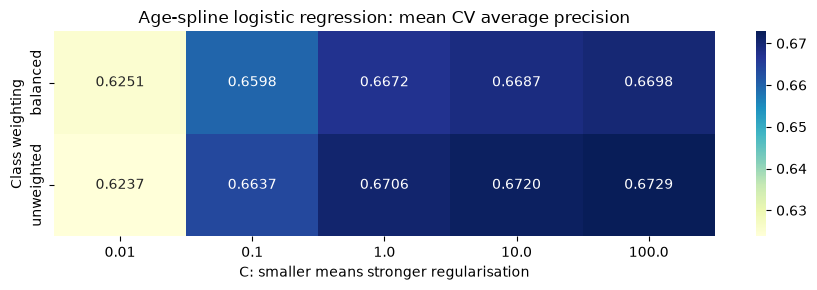

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_results = age_search_results.copy()

# Make the unweighted configuration readable.
plot_results["weight_label"] = (
    plot_results["param_model__class_weight"]
    .fillna("unweighted")
    .astype(str)
)

ap_heatmap = plot_results.pivot(
    index="weight_label",
    columns="param_model__C",
    values="mean_test_average_precision",
)

plt.figure(figsize=(9, 3))

sns.heatmap(
    ap_heatmap,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
)

plt.xlabel("C: smaller means stronger regularisation")
plt.ylabel("Class weighting")
plt.title("Age-spline logistic regression: mean CV average precision")
plt.tight_layout()
plt.show()

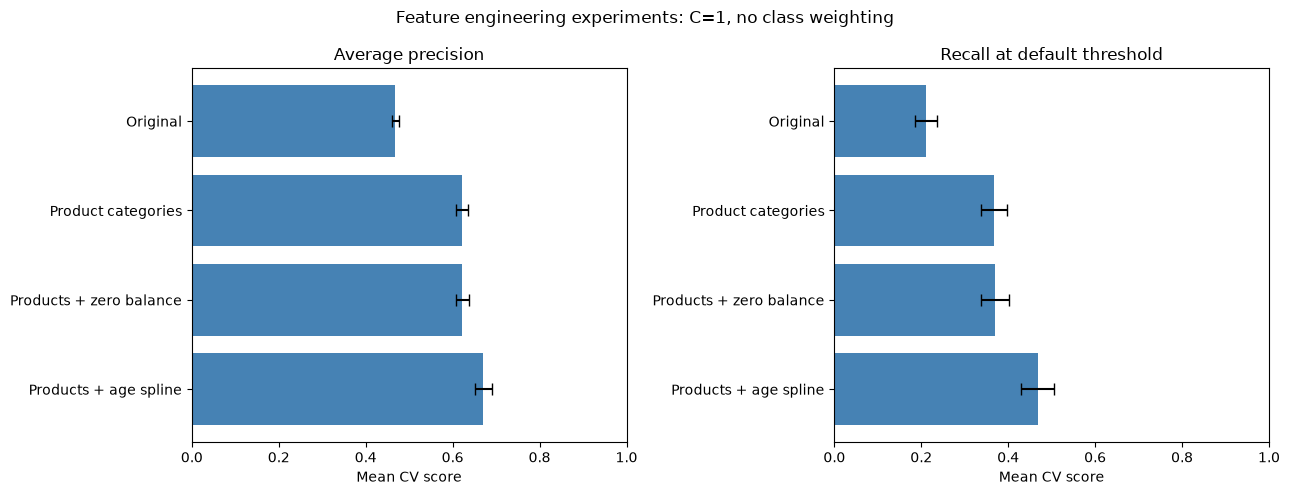

In [62]:
experiment_summaries = {
    "Original": cv_summary,
    "Product categories": product_cv_summary,
    "Products + zero balance": balance_cv_summary,
    "Products + age spline": age_cv_summary,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in zip(
    axes,
    ["average_precision", "recall"],
    ["Average precision", "Recall at default threshold"],
):
    names = list(experiment_summaries)

    means = [
        summary.loc[metric, "mean"]
        for summary in experiment_summaries.values()
    ]

    deviations = [
        summary.loc[metric, "std"]
        for summary in experiment_summaries.values()
    ]

    ax.barh(
        names,
        means,
        xerr=deviations,
        capsize=4,
        color="steelblue",
    )

    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Mean CV score")
    ax.invert_yaxis()

plt.suptitle("Feature engineering experiments: C=1, no class weighting")
plt.tight_layout()
plt.show()

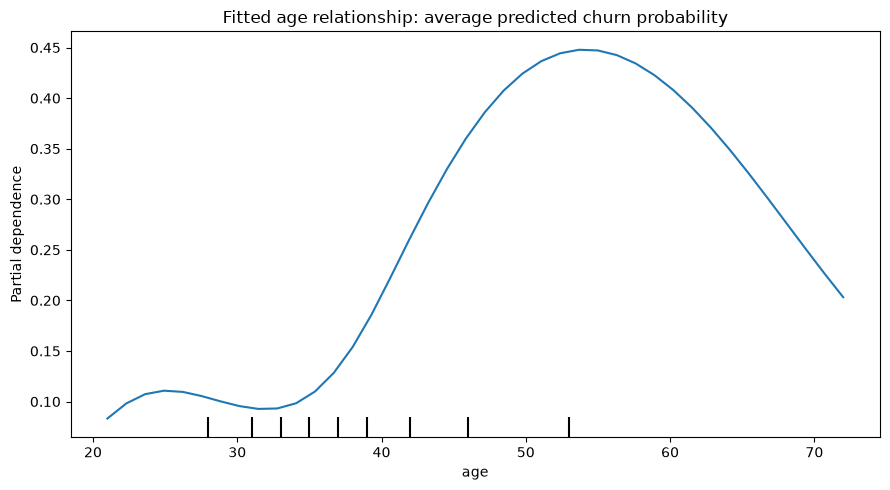

In [64]:
from sklearn.inspection import PartialDependenceDisplay

# Change only a copy used for plotting.
X_plot = X_train.copy()
X_plot["age"] = X_plot["age"].astype("float64")

selected_age_pipeline = age_search.best_estimator_

fig, ax = plt.subplots(figsize=(9, 5))

PartialDependenceDisplay.from_estimator(
    estimator=selected_age_pipeline,
    X=X_plot,
    features=["age"],
    method="brute",
    response_method="predict_proba",
    grid_resolution=40,
    percentiles=(0.01, 0.99),
    ax=ax,
)

ax.set_title("Fitted age relationship: average predicted churn probability")
ax.set_ylabel("Average predicted churn probability")

plt.tight_layout()
plt.show()

In [65]:
print("Selected parameters:", age_search.best_params_)
print("Selected CV average precision:", age_search.best_score_)

Selected parameters: {'model__C': 100, 'model__class_weight': None}
Selected CV average precision: 0.6728663544940398


In [66]:
with mlflow.start_run(run_id=age_search_run_id):
    mlflow.log_figure(
        fig,
        "plots/age_partial_dependence.png",
    )

    mlflow.set_tag(
        "interpretation",
        "Age response rises into the mid-50s then declines; "
        "regularisation tuning adds only a small CV AP improvement.",
    )

print("Age response plot recorded.")

Age response plot recorded.


In [67]:
selected_age_pipeline = age_search.best_estimator_

age_validation_predictions = selected_age_pipeline.predict(X_val)

age_validation_probabilities = selected_age_pipeline.predict_proba(
    X_val
)[:, 1]

age_validation_metrics = {
    "accuracy": accuracy_score(y_val, age_validation_predictions),
    "precision": precision_score(
        y_val, age_validation_predictions, zero_division=0
    ),
    "recall": recall_score(y_val, age_validation_predictions),
    "f1": f1_score(y_val, age_validation_predictions),
    "roc_auc": roc_auc_score(y_val, age_validation_probabilities),
    "average_precision": average_precision_score(
        y_val, age_validation_probabilities
    ),
}

display(
    pd.DataFrame({
        "original_logistic": logistic_metrics,
        "engineered_logistic": pd.Series(age_validation_metrics),
    }).round(4)
)

,original_logistic,engineered_logistic
accuracy,0.8090,0.8555
precision,0.5839,0.7458
recall,0.2138,0.4398
f1,0.3129,0.5533
roc_auc,0.7568,0.8414
average_precision,0.4630,0.6531


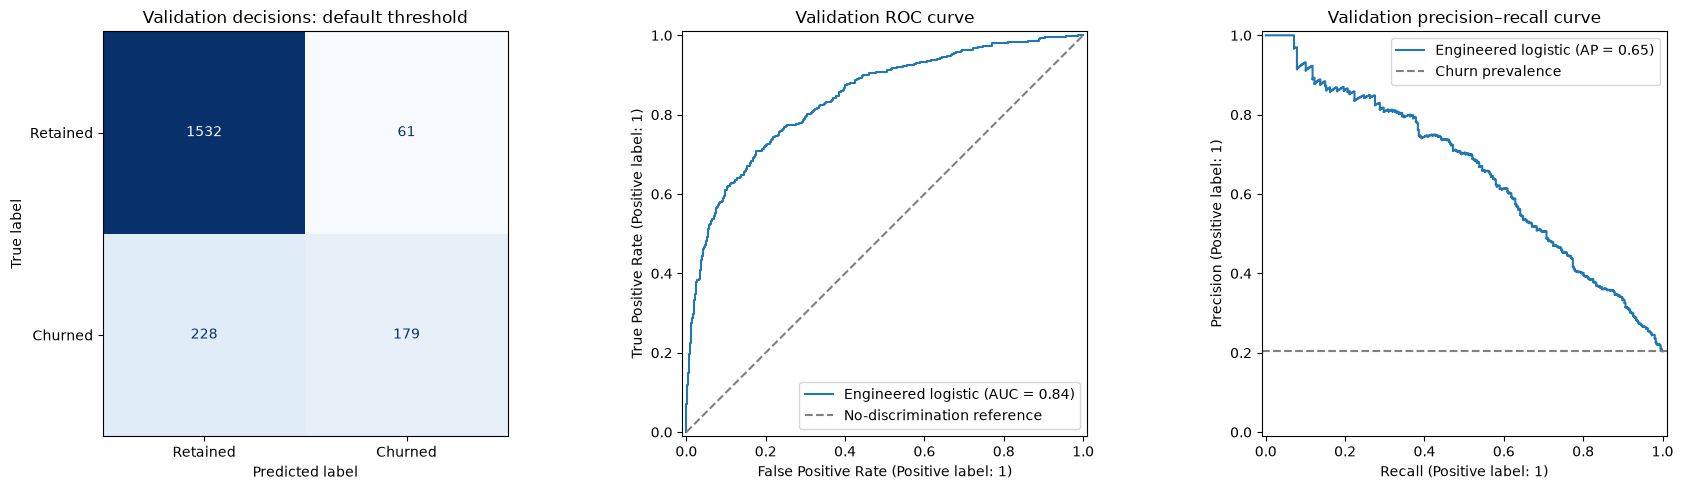

In [69]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

validation_fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    age_validation_predictions,
    labels=[0, 1],
    display_labels=["Retained", "Churned"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Validation decisions: default threshold")

RocCurveDisplay.from_predictions(
    y_val,
    age_validation_probabilities,
    name="Engineered logistic",
    ax=axes[1],
)
axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    label="No-discrimination reference",
)
axes[1].legend()
axes[1].set_title("Validation ROC curve")

PrecisionRecallDisplay.from_predictions(
    y_val,
    age_validation_probabilities,
    name="Engineered logistic",
    ax=axes[2],
)
axes[2].axhline(
    y_val.mean(),
    linestyle="--",
    color="grey",
    label="Churn prevalence",
)
axes[2].legend()
axes[2].set_title("Validation precision–recall curve")

validation_fig.tight_layout()
plt.show()

In [70]:
with mlflow.start_run(
    run_name="logistic-age-spline-validation"
) as age_validation_run:

    mlflow.log_params(
        selected_age_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_param(
        "feature_set",
        "product_categories_plus_age_spline",
    )
    mlflow.log_param("decision_threshold", 0.5)

    mlflow.log_metrics({
        f"validation_{name}": float(value)
        for name, value in age_validation_metrics.items()
    })

    mlflow.log_figure(
        validation_fig,
        "plots/validation_evaluation.png",
    )

    mlflow.log_dict(
        {
            "labels": [0, 1],
            "rows": "actual",
            "columns": "predicted",
            "matrix": confusion_matrix(
                y_val,
                age_validation_predictions,
                labels=[0, 1],
            ).tolist(),
        },
        "validation_confusion_matrix.json",
    )

    mlflow.set_tags({
        "stage": "post_search_validation",
        "source_search_run_id": age_search_run_id,
        "split_reference_run_id": baseline_run_id,
        "test_set_used": "false",
    })

    age_validation_run_id = age_validation_run.info.run_id

print("Saved validation run:", age_validation_run_id)

Saved validation run: 3c7aefce08864219b98ca4e7912f519b


validation_brier_score    0.1102
validation_log_loss       0.3608
dtype: float64

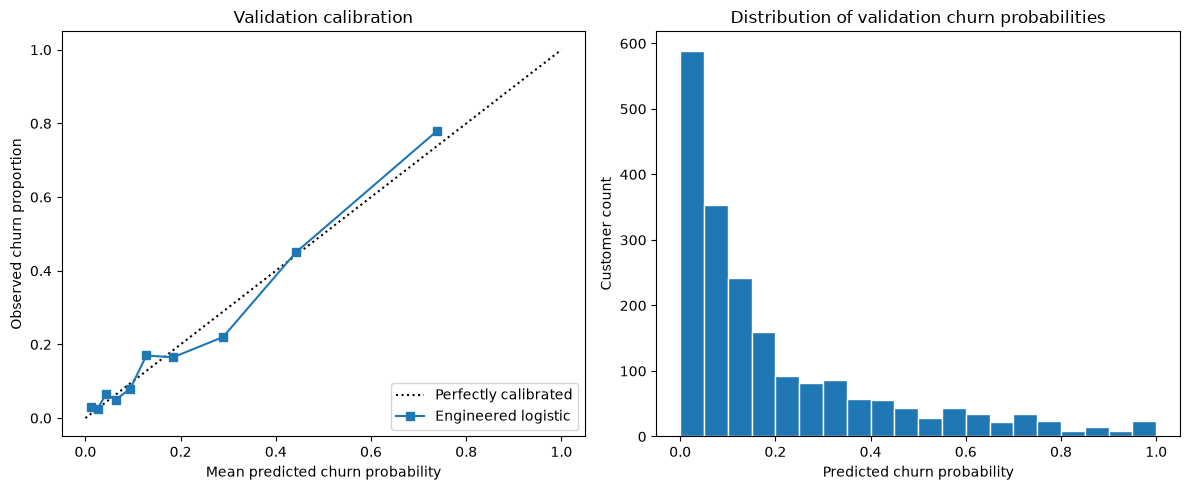

In [71]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss, log_loss

calibration_metrics = {
    "validation_brier_score": brier_score_loss(
        y_val,
        age_validation_probabilities,
    ),
    "validation_log_loss": log_loss(
        y_val,
        age_validation_probabilities,
    ),
}

display(pd.Series(calibration_metrics).round(4))

calibration_fig, axes = plt.subplots(1, 2, figsize=(12, 5))

CalibrationDisplay.from_predictions(
    y_val,
    age_validation_probabilities,
    n_bins=10,
    strategy="quantile",
    name="Engineered logistic",
    ax=axes[0],
)

axes[0].set_title("Validation calibration")
axes[0].set_xlabel("Mean predicted churn probability")
axes[0].set_ylabel("Observed churn proportion")

axes[1].hist(
    age_validation_probabilities,
    bins=20,
    range=(0, 1),
    edgecolor="white",
)

axes[1].set_title("Distribution of validation churn probabilities")
axes[1].set_xlabel("Predicted churn probability")
axes[1].set_ylabel("Customer count")

calibration_fig.tight_layout()
plt.show()

In [72]:
with mlflow.start_run(run_id=age_validation_run_id):
    mlflow.log_metrics(calibration_metrics)

    mlflow.log_params({
        "calibration_bins": 10,
        "calibration_bin_strategy": "quantile",
    })

    mlflow.log_figure(
        calibration_fig,
        "plots/validation_calibration.png",
    )

print("Calibration assessment recorded.")

Calibration assessment recorded.


In [73]:
display(pd.Series(calibration_metrics).round(4))

validation_brier_score    0.1102
validation_log_loss       0.3608
dtype: float64

In [74]:
import numpy as np

# Everyone receives the same probability, learned from training labels.
baseline_probabilities = np.full(
    len(y_val),
    fill_value=float(y_train.mean()),
)

probability_comparison = pd.DataFrame({
    "constant_probability_baseline": {
        "brier_score": brier_score_loss(
            y_val, baseline_probabilities
        ),
        "log_loss": log_loss(
            y_val, baseline_probabilities
        ),
    },
    "engineered_logistic": {
        "brier_score": brier_score_loss(
            y_val, age_validation_probabilities
        ),
        "log_loss": log_loss(
            y_val, age_validation_probabilities
        ),
    },
})

display(probability_comparison.round(4))

,constant_probability_baseline,engineered_logistic
brier_score,0.1621,0.1102
log_loss,0.5052,0.3608


In [75]:
with mlflow.start_run(run_id=age_validation_run_id):
    mlflow.log_metrics({
        "probability_baseline_brier_score": float(
            probability_comparison.loc[
                "brier_score", "constant_probability_baseline"
            ]
        ),
        "probability_baseline_log_loss": float(
            probability_comparison.loc[
                "log_loss", "constant_probability_baseline"
            ]
        ),
    })

    mlflow.log_dict(
        probability_comparison.to_dict(),
        "probability_score_comparison.json",
    )

print("Probability comparison recorded.")

Probability comparison recorded.


In [76]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    age_validation_probabilities,
)

# The final precision/recall point has no corresponding threshold.
threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "precision": precisions[:-1],
    "recall": recalls[:-1],
})

denominator = (
    threshold_results["precision"] + threshold_results["recall"]
)

threshold_results["f1"] = (
    2
    * threshold_results["precision"]
    * threshold_results["recall"]
    / denominator.replace(0, np.nan)
).fillna(0)

# If several thresholds tie, choose the highest threshold.
selected_row = (
    threshold_results
    .sort_values(
        ["f1", "threshold"],
        ascending=[False, False],
    )
    .iloc[0]
)

selected_threshold = float(selected_row["threshold"])

print("Selected threshold:", selected_threshold)
display(selected_row.to_frame("validation_result"))

Selected threshold: 0.34759955313554514


,validation_result
threshold,0.347600
precision,0.613861
recall,0.609337
f1,0.611591


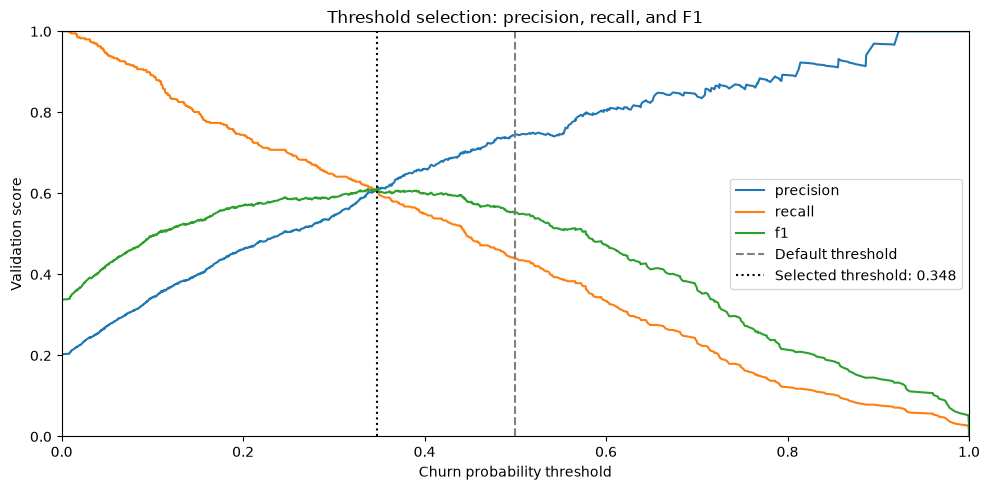

In [77]:
threshold_fig, ax = plt.subplots(figsize=(10, 5))

for metric in ["precision", "recall", "f1"]:
    ax.plot(
        threshold_results["threshold"],
        threshold_results[metric],
        label=metric,
    )

ax.axvline(
    0.5,
    color="grey",
    linestyle="--",
    label="Default threshold",
)

ax.axvline(
    selected_threshold,
    color="black",
    linestyle=":",
    label=f"Selected threshold: {selected_threshold:.3f}",
)

ax.set(
    xlabel="Churn probability threshold",
    ylabel="Validation score",
    title="Threshold selection: precision, recall, and F1",
    xlim=(0, 1),
    ylim=(0, 1),
)

ax.legend()
threshold_fig.tight_layout()
plt.show()

In [79]:
threshold_comparison_rows = []

for label, threshold in [
    ("default", 0.5),
    ("selected_f1", selected_threshold),
]:
    predictions = (
        age_validation_probabilities >= threshold
    ).astype("int64")

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1],
    ).ravel()

    threshold_comparison_rows.append({
        "setting": label,
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "flagged_customers": int(predictions.sum()),
        "detected_churners": int(tp),
        "missed_churners": int(fn),
        "false_alarms": int(fp),
    })

threshold_comparison = pd.DataFrame(
    threshold_comparison_rows
).set_index("setting")

display(threshold_comparison.round(4))

,threshold,precision,recall,f1,flagged_customers,detected_churners,missed_churners,false_alarms
setting,,,,,,,,
default,0.5000,0.7458,0.4398,0.5533,240,179,228,61
selected_f1,0.3476,0.6139,0.6093,0.6116,404,248,159,156


In [80]:
with mlflow.start_run(
    run_name="logistic-age-spline-threshold-selection"
) as threshold_run:

    mlflow.log_params({
        "selection_criterion": "maximum_validation_f1",
        "tie_break": "highest_threshold",
        "selected_threshold": selected_threshold,
        "default_threshold": 0.5,
    })

    mlflow.log_metrics({
        "selected_validation_precision": float(selected_row["precision"]),
        "selected_validation_recall": float(selected_row["recall"]),
        "selected_validation_f1": float(selected_row["f1"]),
    })

    mlflow.log_figure(
        threshold_fig,
        "plots/threshold_tradeoffs.png",
    )

    mlflow.log_dict(
        threshold_comparison.to_dict(orient="index"),
        "threshold_comparison.json",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = Path(temporary_directory) / "threshold_results.csv"
        threshold_results.to_csv(results_path, index=False)
        mlflow.log_artifact(str(results_path))

    mlflow.set_tags({
        "source_search_run_id": age_search_run_id,
        "source_validation_run_id": age_validation_run_id,
        "test_set_used": "false",
    })

    threshold_run_id = threshold_run.info.run_id

A threshold selected to maximise validation F1 increased churn recall from 43.98% to 60.93%, while reducing precision from 74.58% to 61.39%. It flagged 20.2% of validation customers, compared with 12.0% at the default threshold

In [81]:
# Keep the validation rows and their original indices aligned.
error_analysis = X_val.copy()

error_analysis["actual_churn"] = y_val
error_analysis["churn_probability"] = age_validation_probabilities

error_analysis["predicted_churn"] = (
    error_analysis["churn_probability"] >= selected_threshold
).astype("int64")

error_analysis["outcome"] = np.select(
    [
        (error_analysis["actual_churn"] == 1)
        & (error_analysis["predicted_churn"] == 1),

        (error_analysis["actual_churn"] == 1)
        & (error_analysis["predicted_churn"] == 0),

        (error_analysis["actual_churn"] == 0)
        & (error_analysis["predicted_churn"] == 1),
    ],
    ["true_positive", "false_negative", "false_positive"],
    default="true_negative",
)

display(error_analysis["outcome"].value_counts())

outcome
true_negative     1437
true_positive      248
false_negative     159
false_positive     156
Name: count, dtype: int64

In [82]:
country_error_rows = []

for country, group in error_analysis.groupby("country"):
    tn, fp, fn, tp = confusion_matrix(
        group["actual_churn"],
        group["predicted_churn"],
        labels=[0, 1],
    ).ravel()

    country_error_rows.append({
        "country": country,
        "customers": len(group),
        "actual_churners": int(tp + fn),
        "detected_churners": int(tp),
        "missed_churners": int(fn),
        "false_alarms": int(fp),
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "false_positive_rate": fp / (fp + tn) if fp + tn else np.nan,
        "precision": tp / (tp + fp) if tp + fp else np.nan,
    })

country_errors = pd.DataFrame(
    country_error_rows
).set_index("country")

display(country_errors.round(4))

,customers,actual_churners,detected_churners,missed_churners,false_alarms,recall,false_positive_rate,precision
country,,,,,,,,
France,1013,148,82,66,63,0.5541,0.0728,0.5655
Germany,501,174,122,52,62,0.7011,0.1896,0.6630
Spain,486,85,44,41,31,0.5176,0.0773,0.5867


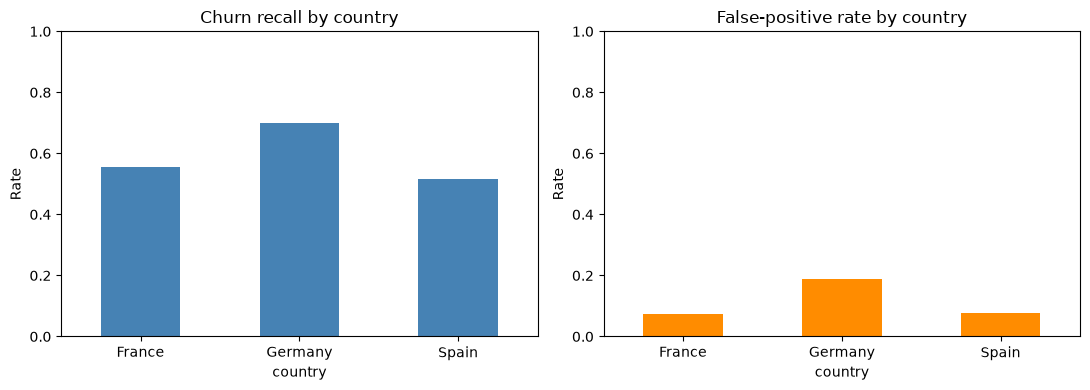

In [83]:
error_fig, axes = plt.subplots(1, 2, figsize=(11, 4))

country_errors["recall"].plot.bar(
    ax=axes[0],
    color="steelblue",
    rot=0,
)
axes[0].set_title("Churn recall by country")

country_errors["false_positive_rate"].plot.bar(
    ax=axes[1],
    color="darkorange",
    rot=0,
)
axes[1].set_title("False-positive rate by country")

for ax in axes:
    ax.set_ylim(0, 1)
    ax.set_ylabel("Rate")

error_fig.tight_layout()
plt.show()

At the shared threshold, recall and false-positive rates vary across countries. Germany has higher churn detection alongside more false alarms among retained customers. Overall metrics therefore conceal subgroup differences.

In [84]:
with mlflow.start_run(run_id=threshold_run_id):
    mlflow.log_figure(
        error_fig,
        "plots/country_error_rates.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = Path(temporary_directory) / "country_error_analysis.csv"
        country_errors.to_csv(results_path)

        mlflow.log_artifact(
            str(results_path),
            artifact_path="error_analysis",
        )

In [85]:
error_analysis["age_group"] = pd.cut(
    error_analysis["age"],
    bins=[0, 30, 40, 50, 60, float("inf")],
    labels=["Under 30", "30–39", "40–49", "50–59", "60+"],
    right=False,
)

In [86]:
def summarise_group_errors(data, group_column):
    rows = []

    for group_name, group in data.groupby(
        group_column,
        observed=True,
    ):
        tn, fp, fn, tp = confusion_matrix(
            group["actual_churn"],
            group["predicted_churn"],
            labels=[0, 1],
        ).ravel()

        rows.append({
            group_column: group_name,
            "customers": len(group),
            "actual_churners": int(tp + fn),
            "actual_retained": int(tn + fp),
            "detected_churners": int(tp),
            "missed_churners": int(fn),
            "false_alarms": int(fp),
            "recall": tp / (tp + fn) if tp + fn else np.nan,
            "false_positive_rate": (
                fp / (fp + tn) if fp + tn else np.nan
            ),
            "precision": tp / (tp + fp) if tp + fp else np.nan,
        })

    return pd.DataFrame(rows).set_index(group_column)

In [87]:
subgroup_errors = {}

for feature in ["age_group", "products_number", "gender"]:
    subgroup_errors[feature] = summarise_group_errors(
        error_analysis,
        feature,
    )

    print(f"\nError analysis: {feature}")
    display(subgroup_errors[feature].round(4))


Error analysis: age_group


,customers,actual_churners,actual_retained,detected_churners,missed_churners,false_alarms,recall,false_positive_rate,precision
age_group,,,,,,,,,
Under 30,339,26,313,5,21,5,0.1923,0.0160,0.5000
30–39,845,95,750,16,79,14,0.1684,0.0187,0.5333
40–49,535,156,379,113,43,92,0.7244,0.2427,0.5512
50–59,171,99,72,90,9,37,0.9091,0.5139,0.7087
60+,110,31,79,24,7,8,0.7742,0.1013,0.7500



Error analysis: products_number


,customers,actual_churners,actual_retained,detected_churners,missed_churners,false_alarms,recall,false_positive_rate,precision
products_number,,,,,,,,,
1,1034,293,741,191,102,131,0.6519,0.1768,0.5932
2,910,69,841,12,57,14,0.1739,0.0166,0.4615
3,45,34,11,34,0,11,1.0000,1.0000,0.7556
4,11,11,0,11,0,0,1.0000,NaN,1.0000



Error analysis: gender


,customers,actual_churners,actual_retained,detected_churners,missed_churners,false_alarms,recall,false_positive_rate,precision
gender,,,,,,,,,
Female,889,213,676,138,75,86,0.6479,0.1272,0.6161
Male,1111,194,917,110,84,70,0.5670,0.0763,0.6111


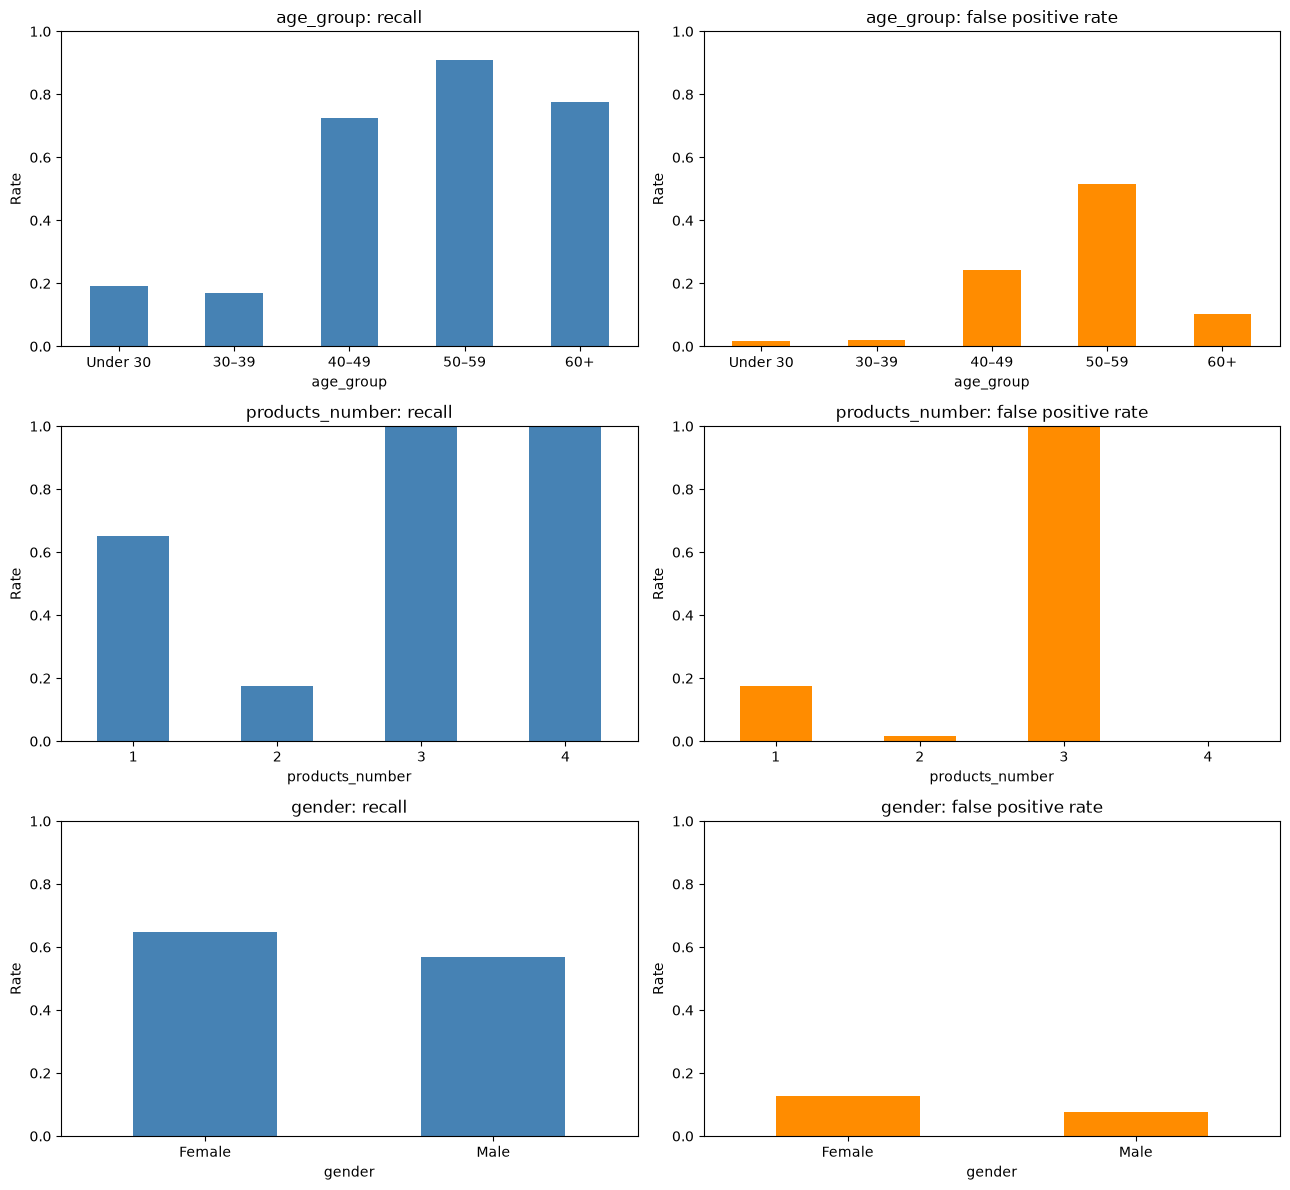

In [88]:
subgroup_fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 12),
)

for row, (feature, summary) in enumerate(subgroup_errors.items()):
    for column, metric in enumerate(
        ["recall", "false_positive_rate"]
    ):
        ax = axes[row, column]

        summary[metric].plot.bar(
            ax=ax,
            color="steelblue" if column == 0 else "darkorange",
            rot=0,
        )

        ax.set_title(f"{feature}: {metric.replace('_', ' ')}")
        ax.set_ylim(0, 1)
        ax.set_ylabel("Rate")

subgroup_fig.tight_layout()
plt.show()

In [89]:
with mlflow.start_run(run_id=threshold_run_id):
    mlflow.log_figure(
        subgroup_fig,
        "plots/subgroup_error_rates.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        for feature, summary in subgroup_errors.items():
            results_path = (
                Path(temporary_directory)
                / f"{feature}_errors.csv"
            )

            summary.to_csv(results_path)

            mlflow.log_artifact(
                str(results_path),
                artifact_path="error_analysis",
            )

print("Subgroup diagnostics recorded.")

Subgroup diagnostics recorded.


At the selected threshold, the model misses many younger churners and customers holding two products. It flags all three-product customers, producing both complete churn detection and substantial false alarms within that small group. Performance also varies across demographic groups.


In [90]:
fitted_preprocessor = selected_age_pipeline.named_steps["preprocessor"]
fitted_model = selected_age_pipeline.named_steps["model"]

coefficient_table = pd.DataFrame({
    "feature": fitted_preprocessor.get_feature_names_out(),
    "coefficient": fitted_model.coef_[0],
})

display(
    coefficient_table
    .sort_values("coefficient")
    .round(4)
)

,feature,coefficient
15,categorical__products_number_2,-4.0043
14,categorical__products_number_1,-2.4836
19,binary__active_member,-1.0071
8,age__age_sp_4,-0.3144
4,age__age_sp_0,-0.2944
6,age__age_sp_2,-0.1376
18,binary__credit_card,-0.1292
1,numeric__tenure,-0.0273
0,numeric__credit_score,-0.0220
2,numeric__balance,-0.0010


In [91]:
coefficients = coefficient_table.set_index("feature")["coefficient"]

comparisons = {
    "Germany vs France": (
        "categorical__country_Germany",
        "categorical__country_France",
    ),
    "Spain vs France": (
        "categorical__country_Spain",
        "categorical__country_France",
    ),
    "Female vs Male": (
        "categorical__gender_Female",
        "categorical__gender_Male",
    ),
    "2 products vs 1": (
        "categorical__products_number_2",
        "categorical__products_number_1",
    ),
    "3 products vs 1": (
        "categorical__products_number_3",
        "categorical__products_number_1",
    ),
    "4 products vs 1": (
        "categorical__products_number_4",
        "categorical__products_number_1",
    ),
}

comparison_rows = []

for label, (category, reference) in comparisons.items():
    difference = coefficients[category] - coefficients[reference]

    comparison_rows.append({
        "comparison": label,
        "log_odds_difference": difference,
        "odds_ratio": np.exp(difference),
    })

category_effects = pd.DataFrame(
    comparison_rows
).set_index("comparison")

display(category_effects.round(4))

,log_odds_difference,odds_ratio
comparison,,
Germany vs France,0.8484,2.3360
Spain vs France,0.0113,1.0113
Female vs Male,0.5119,1.6685
2 products vs 1,-1.5207,0.2186
3 products vs 1,2.7070,14.9844
4 products vs 1,9.7527,17200.7692


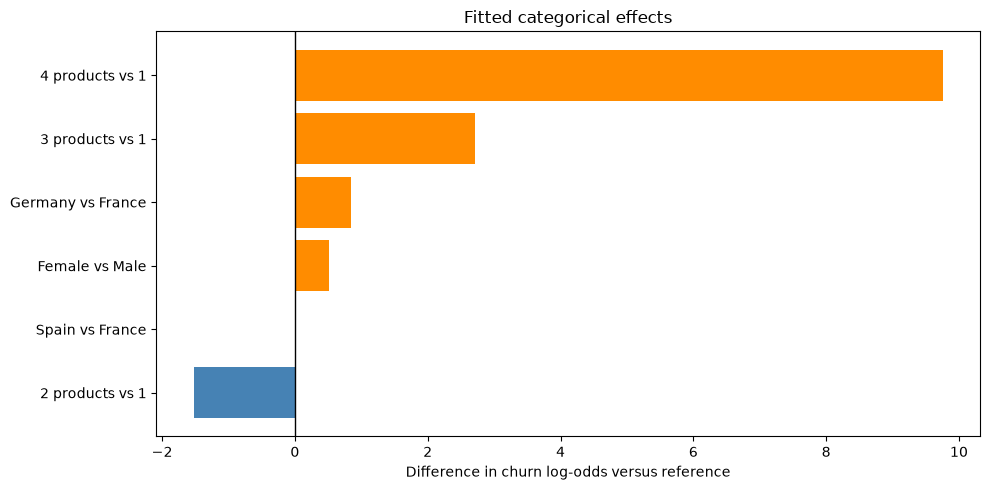

In [92]:
coefficient_fig, ax = plt.subplots(figsize=(10, 5))

effects_to_plot = category_effects.sort_values(
    "log_odds_difference"
)

colors = [
    "steelblue" if value < 0 else "darkorange"
    for value in effects_to_plot["log_odds_difference"]
]

ax.barh(
    effects_to_plot.index,
    effects_to_plot["log_odds_difference"],
    color=colors,
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Difference in churn log-odds versus reference")
ax.set_title("Fitted categorical effects")

coefficient_fig.tight_layout()
plt.show()

The four-product group had uniformly positive training outcomes, producing an extreme fitted coefficient. Its odds ratio is not a reliable population estimate.

In [93]:
with mlflow.start_run(run_id=age_search_run_id):
    mlflow.log_figure(
        coefficient_fig,
        "plots/category_coefficient_comparisons.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        folder = Path(temporary_directory)

        coefficient_table.to_csv(
            folder / "all_coefficients.csv",
            index=False,
        )

        category_effects.to_csv(
            folder / "category_comparisons.csv",
        )

        mlflow.log_artifacts(
            str(folder),
            artifact_path="interpretation",
        )

In [94]:
from sklearn.tree import DecisionTreeClassifier

tree_numeric_features = [
    "credit_score",
    "age",
    "tenure",
    "balance",
    "products_number",
    "estimated_salary",
]

tree_categorical_features = ["country", "gender"]

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", tree_numeric_features),

        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            tree_categorical_features,
        ),

        ("binary", "passthrough", binary_features),
    ],
    remainder="drop",
)

tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", tree_preprocessor),

        (
            "model",
            DecisionTreeClassifier(
                max_depth=4,
                min_samples_leaf=20,
                random_state=42,
            ),
        ),
    ]
)

In [95]:
tree_cv_results = cross_validate(
    estimator=tree_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
)

tree_cv_scores = pd.DataFrame({
    metric: tree_cv_results[f"test_{metric}"]
    for metric in scoring
})

tree_cv_scores.index = range(1, 6)
tree_cv_scores.index.name = "fold"

tree_cv_summary = tree_cv_scores.agg(["mean", "std"]).T

display(tree_cv_summary.round(4))

print(
    "Mean training average precision:",
    tree_cv_results["train_average_precision"].mean().round(4),
)

print(
    "Mean held-out CV average precision:",
    tree_cv_results["test_average_precision"].mean().round(4),
)

,mean,std
roc_auc,0.8188,0.0120
average_precision,0.5799,0.0132
precision,0.7526,0.0428
recall,0.3794,0.0455
f1,0.5018,0.0340


Mean training average precision: 0.6009
Mean held-out CV average precision: 0.5799


In [96]:
with mlflow.start_run(
    run_name="decision-tree-depth4-baseline-cv"
) as tree_cv_run:

    mlflow.log_params(
        tree_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "feature_set": "original_predictors_one_hot_text",
        "numeric_scaling": "none",
        "cv_folds": 5,
        "cv_random_state": 42,
    })

    for metric in scoring:
        mlflow.log_metric(
            f"cv_{metric}_mean",
            float(tree_cv_summary.loc[metric, "mean"]),
        )
        mlflow.log_metric(
            f"cv_{metric}_std",
            float(tree_cv_summary.loc[metric, "std"]),
        )

    mlflow.log_metric(
        "training_average_precision_mean",
        float(tree_cv_results["train_average_precision"].mean()),
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = Path(temporary_directory) / "cv_fold_scores.csv"

        fold_details = pd.DataFrame({
            "train_average_precision":
                tree_cv_results["train_average_precision"],
            **{
                f"heldout_{metric}": tree_cv_results[f"test_{metric}"]
                for metric in scoring
            },
        })

        fold_details.index = range(1, 6)
        fold_details.index.name = "fold"
        fold_details.to_csv(results_path)

        mlflow.log_artifact(
            str(results_path),
            artifact_path="cross_validation",
        )

    mlflow.set_tags({
        "stage": "decision_tree_baseline",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

    tree_cv_run_id = tree_cv_run.info.run_id

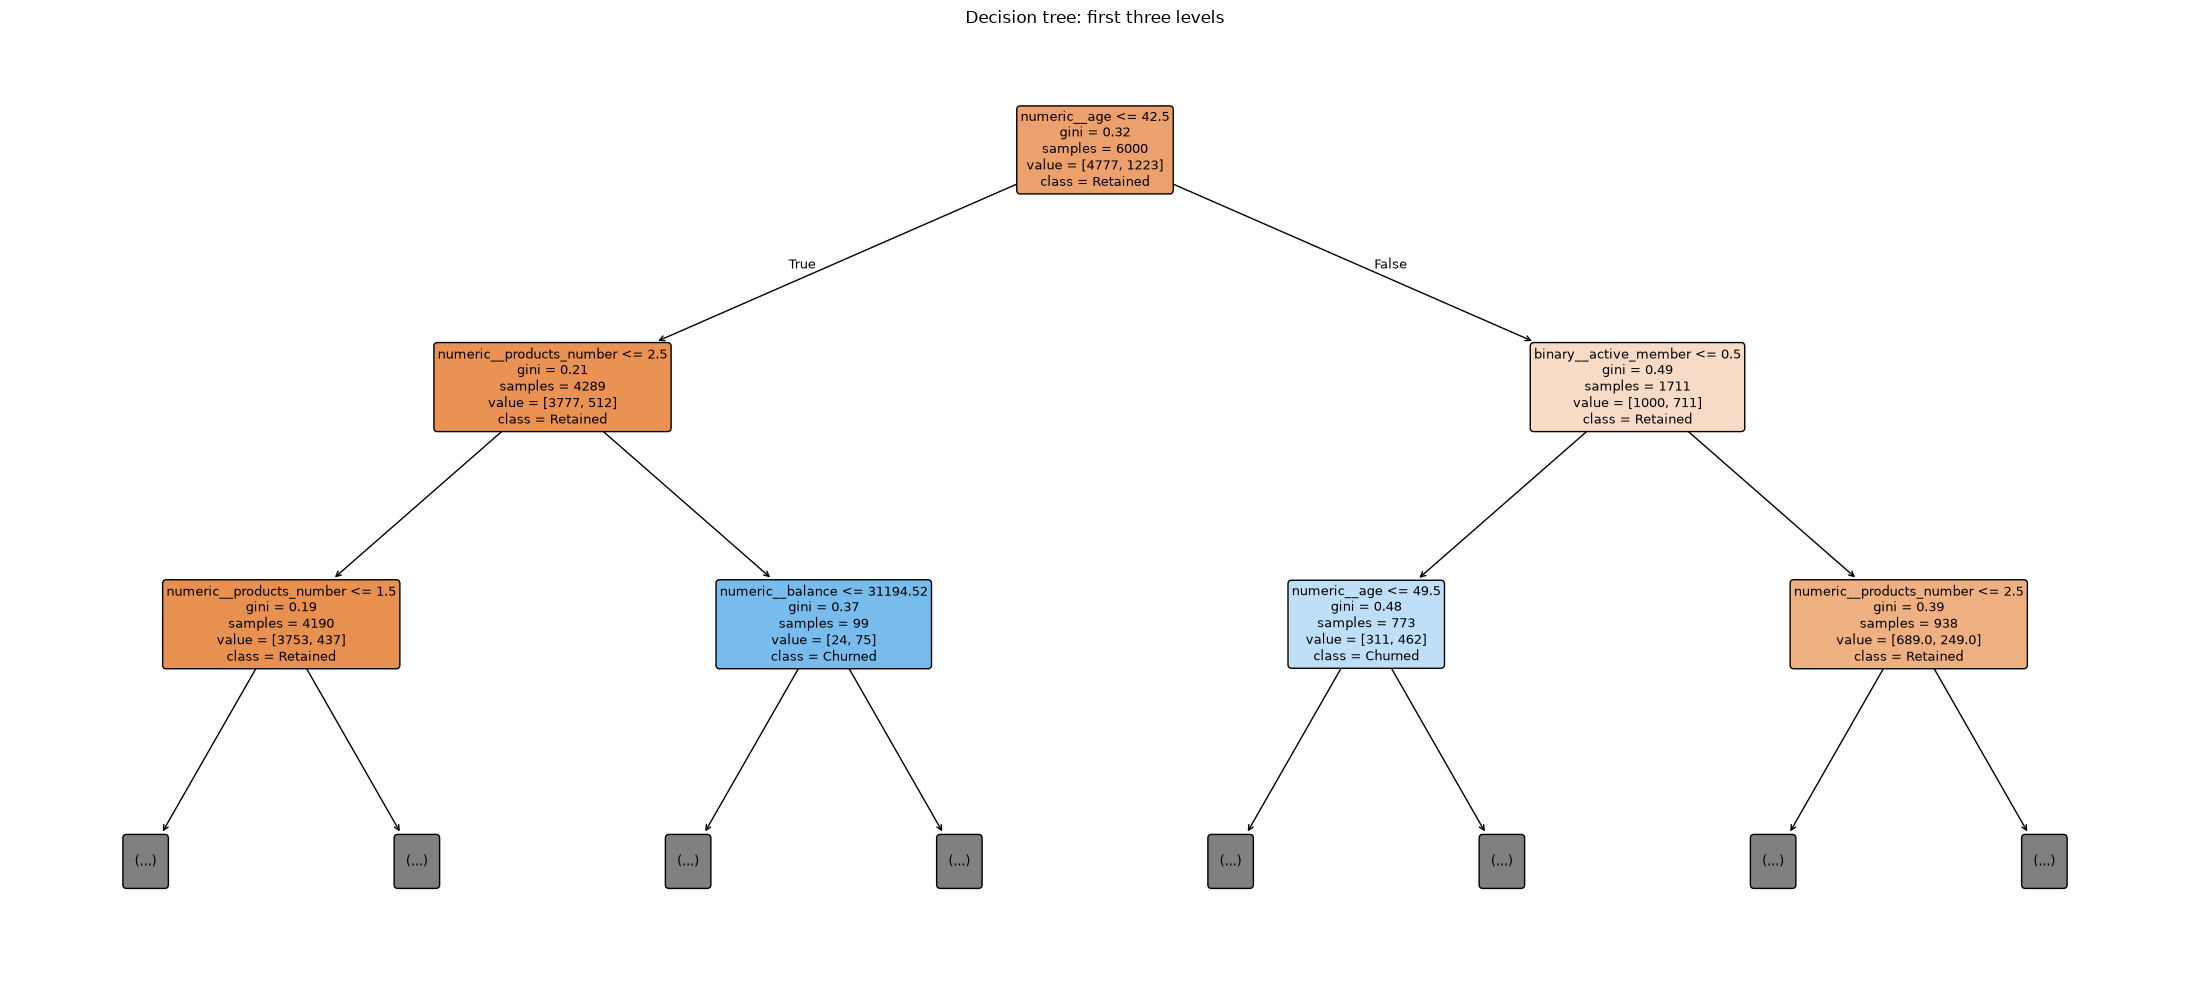

In [97]:
from sklearn.tree import plot_tree

tree_pipeline.fit(X_train, y_train)

fitted_tree = tree_pipeline.named_steps["model"]

tree_feature_names = (
    tree_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

tree_fig, ax = plt.subplots(figsize=(22, 10))

plot_tree(
    fitted_tree,
    feature_names=tree_feature_names,
    class_names=["Retained", "Churned"],
    max_depth=2,
    filled=True,
    rounded=True,
    proportion=False,
    precision=2,
    fontsize=9,
    ax=ax,
)

ax.set_title("Decision tree: first three levels")
tree_fig.tight_layout()
plt.show()

In [98]:
with mlflow.start_run(run_id=tree_cv_run_id):
    mlflow.log_figure(
        tree_fig,
        "plots/tree_first_three_levels.png",
    )

    mlflow.log_metrics({
        "fitted_tree_depth": fitted_tree.get_depth(),
        "fitted_tree_leaves": fitted_tree.get_n_leaves(),
    })

In [99]:
tree_parameter_grid = {
    "model__max_depth": [2, 4, 6, 8, 12, None],
    "model__min_samples_leaf": [5, 20, 50],
}

tree_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_parameter_grid,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

tree_search.fit(X_train, y_train)

tree_search_results = pd.DataFrame(tree_search.cv_results_)

print("Selected parameters:", tree_search.best_params_)
print("Selected CV average precision:", tree_search.best_score_)

display(
    tree_search_results[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "mean_train_average_precision",
            "mean_test_average_precision",
            "std_test_average_precision",
            "mean_test_roc_auc",
            "mean_test_precision",
            "mean_test_recall",
            "mean_test_f1",
        ]
    ]
    .sort_values("mean_test_average_precision", ascending=False)
    .round(4)
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Selected parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 5}
Selected CV average precision: 0.6268217504480282


,param_model__max_depth,param_model__min_samples_leaf,mean_train_average_precision,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,mean_test_precision,mean_test_recall,mean_test_f1
6,6,5,0.6989,0.6268,0.0154,0.8314,0.7364,0.4194,0.5314
7,6,20,0.6856,0.6211,0.0176,0.8338,0.7143,0.4309,0.5364
10,8,20,0.7307,0.6157,0.0237,0.8212,0.6589,0.4759,0.5523
16,None,20,0.7514,0.6050,0.0204,0.8091,0.6564,0.4808,0.5547
17,None,50,0.6620,0.6046,0.0262,0.8226,0.7143,0.3941,0.5064
14,12,50,0.6620,0.6046,0.0262,0.8226,0.7143,0.3941,0.5064
11,8,50,0.6591,0.6045,0.0254,0.8242,0.7143,0.3941,0.5064
13,12,20,0.7504,0.6042,0.0199,0.8080,0.6553,0.4783,0.5526
8,6,50,0.6432,0.6009,0.0233,0.8253,0.7155,0.3900,0.5031
9,8,5,0.7722,0.5962,0.0143,0.8082,0.6580,0.4448,0.5305


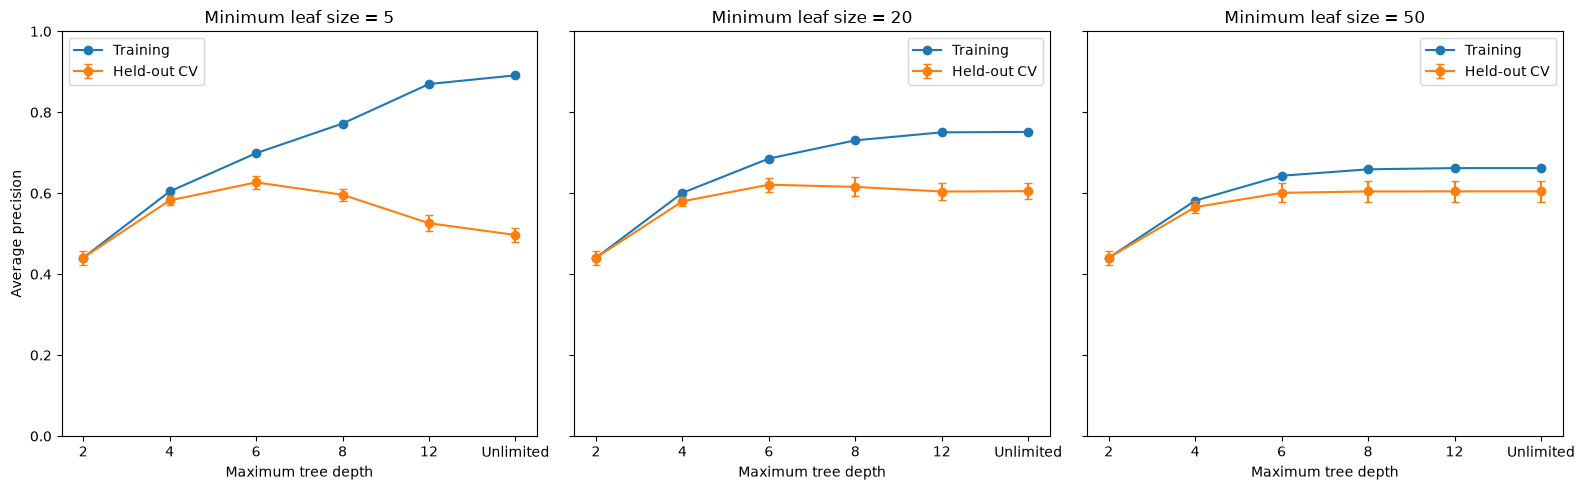

In [100]:
depth_values = [2, 4, 6, 8, 12, None]
depth_labels = ["2", "4", "6", "8", "12", "Unlimited"]

tree_complexity_fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5),
    sharey=True,
)

for ax, leaf_size in zip(axes, [5, 20, 50]):
    subset = tree_search_results.loc[
        tree_search_results["param_model__min_samples_leaf"]
        == leaf_size
    ]

    train_means = []
    heldout_means = []
    heldout_stds = []

    for depth in depth_values:
        if depth is None:
            row = subset.loc[
                subset["param_model__max_depth"].isna()
            ].iloc[0]
        else:
            row = subset.loc[
                subset["param_model__max_depth"] == depth
            ].iloc[0]

        train_means.append(row["mean_train_average_precision"])
        heldout_means.append(row["mean_test_average_precision"])
        heldout_stds.append(row["std_test_average_precision"])

    positions = np.arange(len(depth_values))

    ax.plot(
        positions, train_means,
        marker="o", label="Training",
    )

    ax.errorbar(
        positions, heldout_means,
        yerr=heldout_stds,
        marker="o", capsize=3,
        label="Held-out CV",
    )

    ax.set_xticks(positions, depth_labels)
    ax.set_xlabel("Maximum tree depth")
    ax.set_title(f"Minimum leaf size = {leaf_size}")
    ax.set_ylim(0, 1)
    ax.legend()

axes[0].set_ylabel("Average precision")
tree_complexity_fig.tight_layout()
plt.show()

Increasing depth improved held-out average precision up to depth six. Further depth with small leaves increased training performance while reducing held-out performance, indicating overfitting. The selected tree improved over the initial tree but remained below engineered logistic regression.

In [101]:
with mlflow.start_run(
    run_name="decision-tree-depth-leaf-grid-search"
) as tree_search_run:

    mlflow.log_params(
        tree_search.best_estimator_.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "cv_folds": 5,
        "cv_random_state": 42,
        "selection_metric": "average_precision",
        "candidate_count": len(tree_search_results),
        "feature_set": "original_predictors_one_hot_text",
    })

    best_index = tree_search.best_index_

    for metric in scoring:
        for statistic in ["mean", "std"]:
            mlflow.log_metric(
                f"selected_cv_{metric}_{statistic}",
                float(tree_search_results.loc[
                    best_index,
                    f"{statistic}_test_{metric}",
                ]),
            )

    mlflow.log_metric(
        "selected_training_average_precision_mean",
        float(tree_search_results.loc[
            best_index,
            "mean_train_average_precision",
        ]),
    )

    mlflow.log_dict(
        tree_parameter_grid,
        "search/parameter_grid.json",
    )

    mlflow.log_figure(
        tree_complexity_fig,
        "plots/tree_complexity.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = Path(temporary_directory) / "tree_search_results.csv"
        tree_search_results.to_csv(results_path, index=False)

        mlflow.log_artifact(
            str(results_path),
            artifact_path="search",
        )

    mlflow.set_tags({
        "stage": "hyperparameter_search",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

    tree_search_run_id = tree_search_run.info.run_id

print("Tree search recorded:", tree_search_run_id)

Tree search recorded: 6758ac9e473c4669a4b8951f875237e3


In [102]:
selected_tree_pipeline = tree_search.best_estimator_

with mlflow.start_run(run_id=tree_search_run_id):
    tree_model_info = mlflow.sklearn.log_model(
        sk_model=selected_tree_pipeline,
        name="selected_tree_pipeline",
        signature=signature,
        serialization_format="skops",
        skops_trusted_types=["sklearn.tree._tree.Tree"],
    )

# Verify the saved pipeline using training examples.
loaded_tree_pipeline = mlflow.sklearn.load_model(
    tree_model_info.model_uri
)

sample = X_train.head(20)

np.testing.assert_allclose(
    selected_tree_pipeline.predict_proba(sample),
    loaded_tree_pipeline.predict_proba(sample),
)

print("Verified: saved tree reproduces original probabilities.")

Verified: saved tree reproduces original probabilities.


In [103]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(tree_preprocessor)),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=None,
                min_samples_leaf=5,
                max_features="sqrt",
                bootstrap=True,
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

In [104]:
forest_cv_results = cross_validate(
    estimator=forest_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
)

forest_cv_scores = pd.DataFrame({
    metric: forest_cv_results[f"test_{metric}"]
    for metric in scoring
})

forest_cv_scores.index = range(1, 6)
forest_cv_scores.index.name = "fold"

forest_cv_summary = forest_cv_scores.agg(["mean", "std"]).T

display(forest_cv_summary.round(4))

print(
    "Mean training average precision:",
    forest_cv_results["train_average_precision"].mean().round(4),
)
print(
    "Mean held-out CV average precision:",
    forest_cv_results["test_average_precision"].mean().round(4),
)

,mean,std
roc_auc,0.8545,0.0157
average_precision,0.6851,0.0219
precision,0.8041,0.0387
recall,0.4088,0.0334
f1,0.5412,0.0296


Mean training average precision: 0.9052
Mean held-out CV average precision: 0.6851


In [106]:
with mlflow.start_run(
    run_name="random-forest-300-trees-leaf5-baseline-cv"
) as forest_cv_run:

    mlflow.log_params(
        forest_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "feature_set": "original_predictors_one_hot_text",
        "cv_folds": 5,
        "cv_random_state": 42,
        "numeric_scaling": "none",
    })

    for metric in scoring:
        for statistic in ["mean", "std"]:
            mlflow.log_metric(
                f"cv_{metric}_{statistic}",
                float(forest_cv_summary.loc[metric, statistic]),
            )

    mlflow.log_metric(
        "training_average_precision_mean",
        float(forest_cv_results["train_average_precision"].mean()),
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = Path(temporary_directory) / "cv_fold_scores.csv"

        fold_details = forest_cv_scores.copy()
        fold_details["training_average_precision"] = (
            forest_cv_results["train_average_precision"]
        )
        fold_details.to_csv(results_path)

        mlflow.log_artifact(
            str(results_path),
            artifact_path="cross_validation",
        )

    mlflow.set_tags({
        "stage": "random_forest_baseline",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

    forest_cv_run_id = forest_cv_run.info.run_id

In [107]:
forest_parameter_grid = {
    "model__max_depth": [6, 12, None],
    "model__min_samples_leaf": [5, 20, 50],
    "model__max_features": ["sqrt", 0.7],
}

forest_search = GridSearchCV(
    estimator=forest_pipeline,
    param_grid=forest_parameter_grid,
    scoring=scoring,
    refit="average_precision",
    cv=cv,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=2,
)

forest_search.fit(X_train, y_train)

forest_search_results = pd.DataFrame(forest_search.cv_results_)

print("Selected parameters:", forest_search.best_params_)
print("Selected CV average precision:", forest_search.best_score_)

display(
    forest_search_results[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__max_features",
            "mean_train_average_precision",
            "mean_test_average_precision",
            "std_test_average_precision",
            "mean_test_roc_auc",
            "mean_test_precision",
            "mean_test_recall",
            "mean_test_f1",
        ]
    ]
    .sort_values("mean_test_average_precision", ascending=False)
    .round(4)
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=5; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=20; total time=   0.4s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=20; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=20; total time=   0.3s
[CV] END model__max_depth=6, model__max_features=sqrt, model__min_samples_leaf=20; total time=   0.3s
[CV] END model__max_depth=

,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_train_average_precision,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,mean_test_precision,mean_test_recall,mean_test_f1
3,6,5,0.7,0.7450,0.6884,0.0192,0.8537,0.7938,0.4284,0.5549
16,None,20,0.7,0.7764,0.6875,0.0208,0.8565,0.7671,0.4489,0.5654
10,12,20,0.7,0.7762,0.6874,0.0218,0.8567,0.7711,0.4505,0.5679
6,12,5,sqrt,0.8887,0.6869,0.0198,0.8555,0.7984,0.4137,0.5440
12,None,5,sqrt,0.9052,0.6851,0.0196,0.8545,0.8041,0.4088,0.5412
4,6,20,0.7,0.7302,0.6845,0.0207,0.8548,0.7768,0.4382,0.5592
0,6,5,sqrt,0.7391,0.6825,0.0211,0.8519,0.8480,0.3418,0.4865
15,None,5,0.7,0.9255,0.6820,0.0220,0.8483,0.7420,0.4619,0.5683
9,12,5,0.7,0.9129,0.6817,0.0221,0.8490,0.7463,0.4603,0.5684
1,6,20,sqrt,0.7235,0.6763,0.0195,0.8522,0.8531,0.3123,0.4568


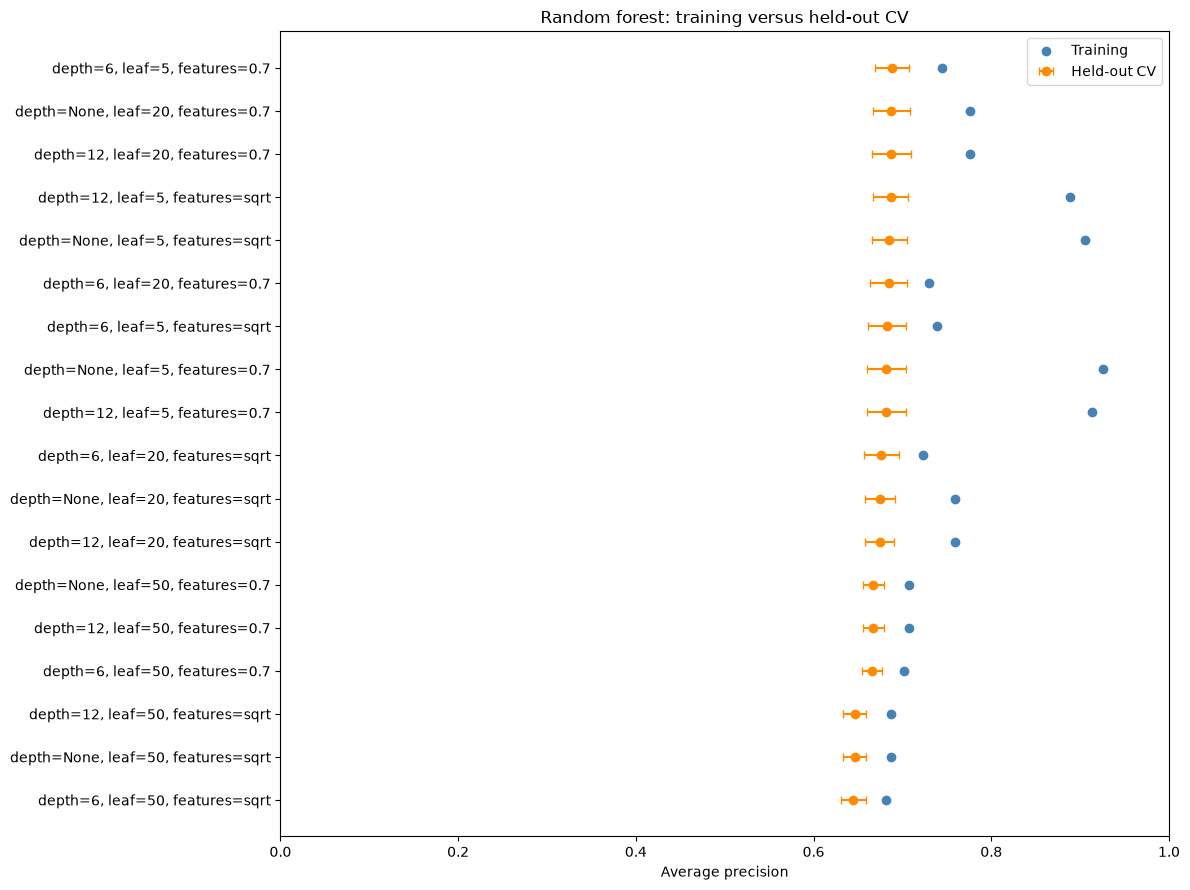

In [108]:
forest_plot_data = forest_search_results.copy()

forest_plot_data["configuration"] = [
    f"depth={depth}, leaf={leaf}, features={features}"
    for depth, leaf, features in zip(
        forest_plot_data["param_model__max_depth"],
        forest_plot_data["param_model__min_samples_leaf"],
        forest_plot_data["param_model__max_features"],
    )
]

forest_plot_data = forest_plot_data.sort_values(
    "mean_test_average_precision"
)

positions = np.arange(len(forest_plot_data))

forest_search_fig, ax = plt.subplots(figsize=(12, 9))

ax.scatter(
    forest_plot_data["mean_train_average_precision"],
    positions,
    label="Training",
    color="steelblue",
)

ax.errorbar(
    forest_plot_data["mean_test_average_precision"],
    positions,
    xerr=forest_plot_data["std_test_average_precision"],
    fmt="o",
    capsize=3,
    label="Held-out CV",
    color="darkorange",
)

ax.set_yticks(
    positions,
    forest_plot_data["configuration"],
)

ax.set_xlim(0, 1)
ax.set_xlabel("Average precision")
ax.set_title("Random forest: training versus held-out CV")
ax.legend()

forest_search_fig.tight_layout()
plt.show()

In [109]:
with mlflow.start_run(
    run_name="random-forest-depth-leaf-features-grid-search"
) as forest_search_run:

    mlflow.log_params(
        forest_search.best_estimator_.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "cv_folds": 5,
        "cv_random_state": 42,
        "selection_metric": "average_precision",
        "candidate_count": len(forest_search_results),
        "feature_set": "original_predictors_one_hot_text",
    })

    best_index = forest_search.best_index_

    for metric in scoring:
        for statistic in ["mean", "std"]:
            mlflow.log_metric(
                f"selected_cv_{metric}_{statistic}",
                float(forest_search_results.loc[
                    best_index,
                    f"{statistic}_test_{metric}",
                ]),
            )

    mlflow.log_metric(
        "selected_training_average_precision_mean",
        float(forest_search_results.loc[
            best_index,
            "mean_train_average_precision",
        ]),
    )

    mlflow.log_dict(
        forest_parameter_grid,
        "search/parameter_grid.json",
    )

    mlflow.log_figure(
        forest_search_fig,
        "plots/forest_training_vs_cv.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = (
            Path(temporary_directory) / "forest_search_results.csv"
        )

        forest_search_results.to_csv(results_path, index=False)

        mlflow.log_artifact(
            str(results_path),
            artifact_path="search",
        )

    mlflow.set_tags({
        "stage": "hyperparameter_search",
        "split_reference_run_id": baseline_run_id,
        "validation_set_used": "false",
        "test_set_used": "false",
    })

    forest_search_run_id = forest_search_run.info.run_id

print("Forest search recorded:", forest_search_run_id)

Forest search recorded: 3dca9f367ee149e4870c95c39f93171a


In [110]:
selected_forest_pipeline = forest_search.best_estimator_

with mlflow.start_run(run_id=forest_search_run_id):
    forest_model_info = mlflow.sklearn.log_model(
        sk_model=selected_forest_pipeline,
        name="selected_forest_pipeline",
        signature=signature,
        serialization_format="skops",
        skops_trusted_types=["sklearn.tree._tree.Tree"],
    )

loaded_forest_pipeline = mlflow.sklearn.load_model(
    forest_model_info.model_uri
)

sample = X_train.head(20)

np.testing.assert_allclose(
    selected_forest_pipeline.predict_proba(sample),
    loaded_forest_pipeline.predict_proba(sample),
)

print("Verified: saved forest reproduces original probabilities.")

Verified: saved forest reproduces original probabilities.


In [111]:
shortlisted_models = {
    "engineered_logistic": age_search.best_estimator_,
    "decision_tree": tree_search.best_estimator_,
    "random_forest": forest_search.best_estimator_,
}

validation_probabilities = {}
validation_comparison_rows = []

for model_name, pipeline in shortlisted_models.items():
    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    validation_probabilities[model_name] = probabilities

    validation_comparison_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_val, predictions),
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "roc_auc": roc_auc_score(y_val, probabilities),
        "average_precision": average_precision_score(
            y_val, probabilities
        ),
        "brier_score": brier_score_loss(
            y_val, probabilities
        ),
        "log_loss": log_loss(y_val, probabilities),
    })

validation_model_comparison = pd.DataFrame(
    validation_comparison_rows
).set_index("model")

display(validation_model_comparison.round(4))

,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,log_loss
model,,,,,,,,
engineered_logistic,0.8555,0.7458,0.4398,0.5533,0.8414,0.6531,0.1102,0.3608
decision_tree,0.8450,0.7680,0.3415,0.4728,0.8441,0.6151,0.1130,0.4198
random_forest,0.8580,0.7783,0.4226,0.5478,0.8558,0.6732,0.1072,0.3506


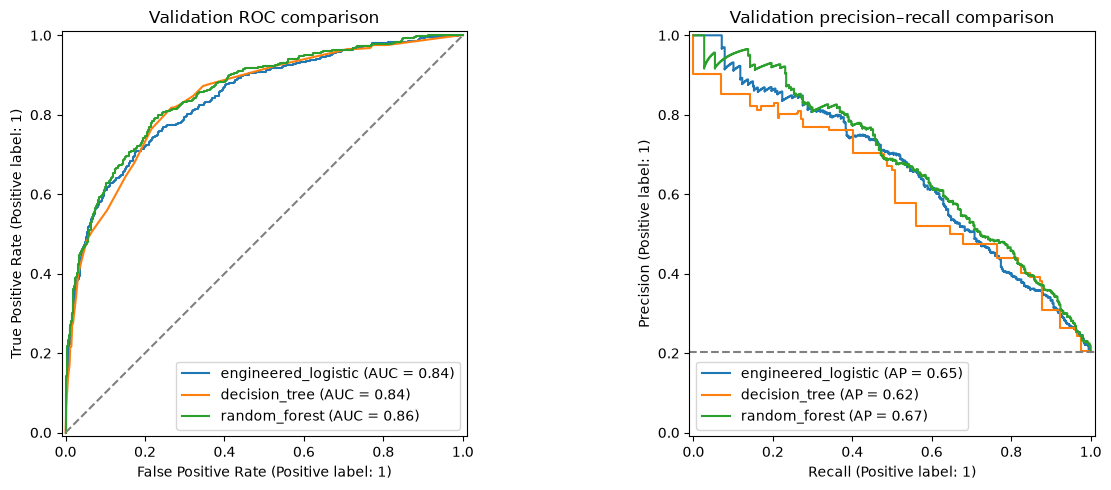

In [113]:
comparison_fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name, probabilities in validation_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[0],
    )

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[1],
    )

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
)
axes[0].set_title("Validation ROC comparison")

axes[1].axhline(
    y_val.mean(),
    linestyle="--",
    color="grey",
)
axes[1].set_title("Validation precision–recall comparison")

comparison_fig.tight_layout()
plt.show()

In [114]:
with mlflow.start_run(
    run_name="shortlisted-models-validation-comparison"
) as model_comparison_run:

    mlflow.log_param("classification_rule", "estimator_default")

    for model_name, row in validation_model_comparison.iterrows():
        mlflow.log_metrics({
            f"{model_name}_validation_{metric}": float(value)
            for metric, value in row.items()
        })

    mlflow.log_dict(
        {
            "engineered_logistic": age_search_run_id,
            "decision_tree": tree_search_run_id,
            "random_forest": forest_search_run_id,
        },
        "source_search_runs.json",
    )

    mlflow.log_figure(
        comparison_fig,
        "plots/validation_model_comparison.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = (
            Path(temporary_directory) / "validation_model_comparison.csv"
        )

        validation_model_comparison.to_csv(results_path)
        mlflow.log_artifact(str(results_path))

    mlflow.set_tags({
        "stage": "shortlist_comparison",
        "split_reference_run_id": baseline_run_id,
        "test_set_used": "false",
    })

    model_comparison_run_id = model_comparison_run.info.run_id

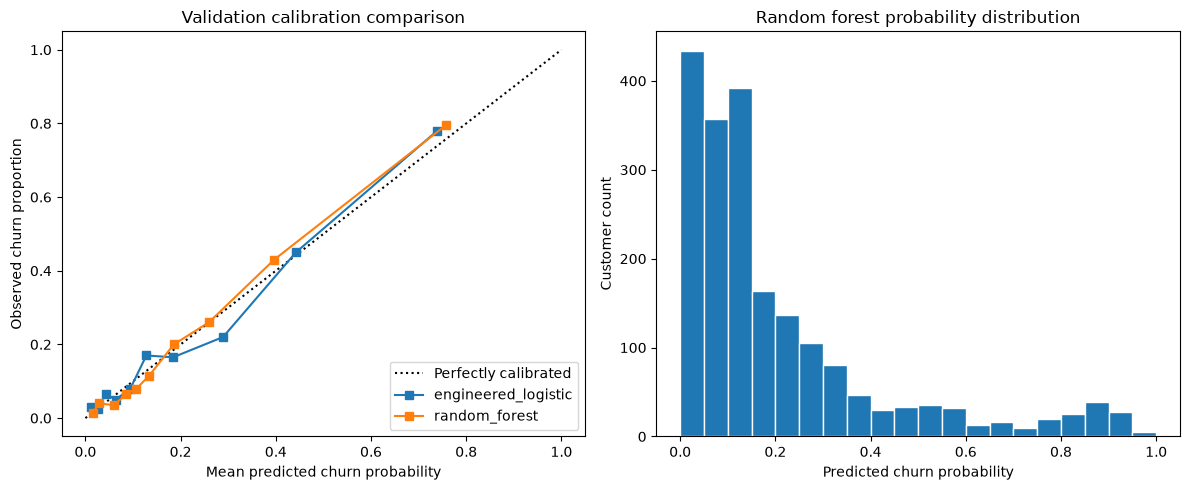

In [116]:
forest_validation_probabilities = validation_probabilities["random_forest"]

forest_calibration_fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
)

# Compare calibration on the same axes.
for model_name in ["engineered_logistic", "random_forest"]:
    CalibrationDisplay.from_predictions(
        y_val,
        validation_probabilities[model_name],
        n_bins=10,
        strategy="quantile",
        name=model_name,
        ax=axes[0],
    )

axes[0].set_title("Validation calibration comparison")
axes[0].set_xlabel("Mean predicted churn probability")
axes[0].set_ylabel("Observed churn proportion")

axes[1].hist(
    forest_validation_probabilities,
    bins=20,
    range=(0, 1),
    edgecolor="white",
)

axes[1].set_title("Random forest probability distribution")
axes[1].set_xlabel("Predicted churn probability")
axes[1].set_ylabel("Customer count")

forest_calibration_fig.tight_layout()
plt.show()

In [117]:
forest_precisions, forest_recalls, forest_thresholds = (
    precision_recall_curve(
        y_val,
        forest_validation_probabilities,
    )
)

forest_threshold_results = pd.DataFrame({
    "threshold": forest_thresholds,
    "precision": forest_precisions[:-1],
    "recall": forest_recalls[:-1],
})

denominator = (
    forest_threshold_results["precision"]
    + forest_threshold_results["recall"]
)

forest_threshold_results["f1"] = (
    2
    * forest_threshold_results["precision"]
    * forest_threshold_results["recall"]
    / denominator.replace(0, np.nan)
).fillna(0)

forest_selected_row = (
    forest_threshold_results
    .sort_values(
        ["f1", "threshold"],
        ascending=[False, False],
    )
    .iloc[0]
)

forest_selected_threshold = float(
    forest_selected_row["threshold"]
)

print("Selected forest threshold:", forest_selected_threshold)
display(forest_selected_row.to_frame("validation_result"))

Selected forest threshold: 0.29537626676780526


,validation_result
threshold,0.295376
precision,0.609524
recall,0.628993
f1,0.619105


In [118]:
operating_point_rows = []

for model_name, threshold in [
    ("engineered_logistic", selected_threshold),
    ("random_forest", forest_selected_threshold),
]:
    probabilities = validation_probabilities[model_name]
    predictions = (probabilities >= threshold).astype("int64")

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1],
    ).ravel()

    operating_point_rows.append({
        "model": model_name,
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(y_val, predictions),
        "f1": f1_score(y_val, predictions),
        "flagged_customers": int(tp + fp),
        "detected_churners": int(tp),
        "missed_churners": int(fn),
        "false_alarms": int(fp),
    })

operating_point_comparison = pd.DataFrame(
    operating_point_rows
).set_index("model")

display(operating_point_comparison.round(4))

,threshold,precision,recall,f1,flagged_customers,detected_churners,missed_churners,false_alarms
model,,,,,,,,
engineered_logistic,0.3476,0.6139,0.6093,0.6116,404,248,159,156
random_forest,0.2954,0.6095,0.6290,0.6191,420,256,151,164


In [119]:
with mlflow.start_run(
    run_name="forest-calibration-and-threshold-selection"
) as forest_threshold_run:

    mlflow.log_params({
        "selection_criterion": "maximum_validation_f1",
        "tie_break": "highest_threshold",
        "selected_threshold": forest_selected_threshold,
        "calibration_bins": 10,
        "calibration_bin_strategy": "quantile",
    })

    mlflow.log_metrics({
        "selected_validation_precision": float(
            forest_selected_row["precision"]
        ),
        "selected_validation_recall": float(
            forest_selected_row["recall"]
        ),
        "selected_validation_f1": float(
            forest_selected_row["f1"]
        ),
    })

    mlflow.log_figure(
        forest_calibration_fig,
        "plots/calibration_comparison.png",
    )

    mlflow.log_dict(
        operating_point_comparison.to_dict(orient="index"),
        "operating_point_comparison.json",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = (
            Path(temporary_directory) / "forest_threshold_results.csv"
        )
        forest_threshold_results.to_csv(results_path, index=False)
        mlflow.log_artifact(str(results_path))

    mlflow.set_tags({
        "source_search_run_id": forest_search_run_id,
        "source_comparison_run_id": model_comparison_run_id,
        "test_set_used": "false",
    })

    forest_threshold_run_id = forest_threshold_run.info.run_id

Random forest is the leading candidate based on training CV and validation ranking performance, with slightly better validation probability scores and selected-threshold F1. Engineered logistic regression remains a competitive, more interpretable alternative.


In [120]:
forest_error_analysis = X_val.copy()

forest_error_analysis["actual_churn"] = y_val

forest_error_analysis["churn_probability"] = (
    forest_validation_probabilities
)

forest_error_analysis["predicted_churn"] = (
    forest_validation_probabilities >= forest_selected_threshold
).astype("int64")

forest_error_analysis["age_group"] = pd.cut(
    forest_error_analysis["age"],
    bins=[0, 30, 40, 50, 60, float("inf")],
    labels=["Under 30", "30–39", "40–49", "50–59", "60+"],
    right=False,
)

In [121]:
forest_subgroup_errors = {}
subgroup_comparisons = {}

for feature in ["country", "age_group", "products_number", "gender"]:
    forest_summary = summarise_group_errors(
        forest_error_analysis,
        feature,
    )

    logistic_summary = summarise_group_errors(
        error_analysis,
        feature,
    )

    forest_subgroup_errors[feature] = forest_summary

    comparison = forest_summary[
        ["customers", "actual_churners", "actual_retained"]
    ].copy()

    for metric in [
        "recall",
        "false_positive_rate",
        "precision",
        "missed_churners",
        "false_alarms",
    ]:
        comparison[f"logistic_{metric}"] = logistic_summary[metric]
        comparison[f"forest_{metric}"] = forest_summary[metric]

    subgroup_comparisons[feature] = comparison

    print(f"\nComparison: {feature}")
    display(comparison.round(4))


Comparison: country


,customers,actual_churners,actual_retained,logistic_recall,forest_recall,logistic_false_positive_rate,forest_false_positive_rate,logistic_precision,forest_precision,logistic_missed_churners,forest_missed_churners,logistic_false_alarms,forest_false_alarms
country,,,,,,,,,,,,,
France,1013,148,865,0.5541,0.6284,0.0728,0.0867,0.5655,0.5536,66,55,63,75
Germany,501,174,327,0.7011,0.6609,0.1896,0.1651,0.6630,0.6805,52,59,62,54
Spain,486,85,401,0.5176,0.5647,0.0773,0.0873,0.5867,0.5783,41,37,31,35



Comparison: age_group


,customers,actual_churners,actual_retained,logistic_recall,forest_recall,logistic_false_positive_rate,forest_false_positive_rate,logistic_precision,forest_precision,logistic_missed_churners,forest_missed_churners,logistic_false_alarms,forest_false_alarms
age_group,,,,,,,,,,,,,
Under 30,339,26,313,0.1923,0.1154,0.0160,0.0064,0.5000,0.6000,21,23,5,2
30–39,845,95,750,0.1684,0.1263,0.0187,0.0107,0.5333,0.6000,79,83,14,8
40–49,535,156,379,0.7244,0.7949,0.2427,0.2955,0.5512,0.5254,43,32,92,112
50–59,171,99,72,0.9091,0.9293,0.5139,0.4583,0.7087,0.7360,9,7,37,33
60+,110,31,79,0.7742,0.8065,0.1013,0.1139,0.7500,0.7353,7,6,8,9



Comparison: products_number


,customers,actual_churners,actual_retained,logistic_recall,forest_recall,logistic_false_positive_rate,forest_false_positive_rate,logistic_precision,forest_precision,logistic_missed_churners,forest_missed_churners,logistic_false_alarms,forest_false_alarms
products_number,,,,,,,,,,,,,
1,1034,293,741,0.6519,0.6587,0.1768,0.1862,0.5932,0.5831,102,100,131,138
2,910,69,841,0.1739,0.2609,0.0166,0.0178,0.4615,0.5455,57,51,14,15
3,45,34,11,1.0000,1.0000,1.0000,1.0000,0.7556,0.7556,0,0,11,11
4,11,11,0,1.0000,1.0000,NaN,NaN,1.0000,1.0000,0,0,0,0



Comparison: gender


,customers,actual_churners,actual_retained,logistic_recall,forest_recall,logistic_false_positive_rate,forest_false_positive_rate,logistic_precision,forest_precision,logistic_missed_churners,forest_missed_churners,logistic_false_alarms,forest_false_alarms
gender,,,,,,,,,,,,,
Female,889,213,676,0.6479,0.6338,0.1272,0.1006,0.6161,0.6650,75,78,86,68
Male,1111,194,917,0.5670,0.6237,0.0763,0.1047,0.6111,0.5576,84,73,70,96


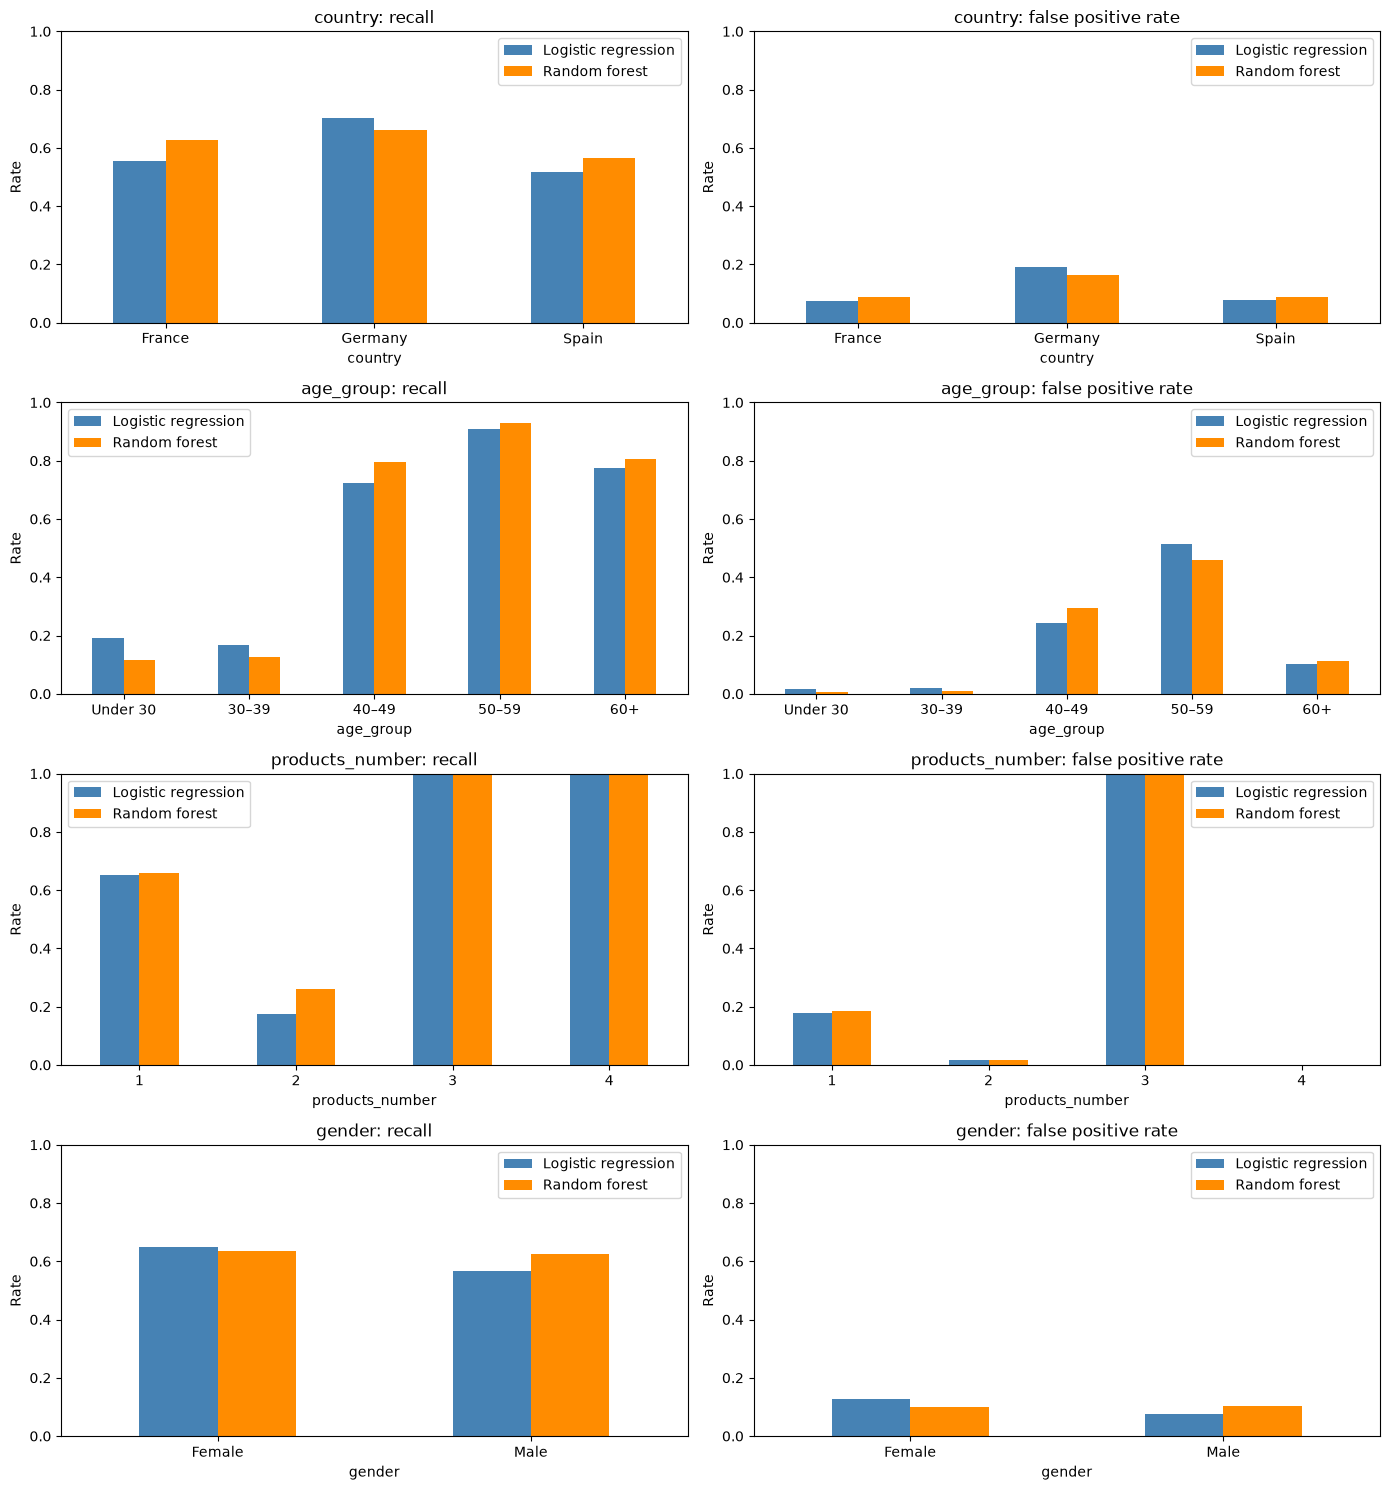

In [122]:
forest_error_fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 15),
)

for row, (feature, comparison) in enumerate(
    subgroup_comparisons.items()
):
    for column, metric in enumerate(
        ["recall", "false_positive_rate"]
    ):
        plot_data = comparison[
            [f"logistic_{metric}", f"forest_{metric}"]
        ].copy()

        plot_data.columns = ["Logistic regression", "Random forest"]

        plot_data.plot.bar(
            ax=axes[row, column],
            rot=0,
            color=["steelblue", "darkorange"],
        )

        axes[row, column].set_title(
            f"{feature}: {metric.replace('_', ' ')}"
        )
        axes[row, column].set_ylim(0, 1)
        axes[row, column].set_ylabel("Rate")

forest_error_fig.tight_layout()
plt.show()

At the selected threshold, the forest misses most churners under 40 and most two-product churners. It flags all three-product customers. Subgroup performance varies, and estimates for small groups are uncertain.

In [123]:
with mlflow.start_run(run_id=forest_threshold_run_id):
    mlflow.log_figure(
        forest_error_fig,
        "plots/subgroup_model_comparison.png",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        for feature, comparison in subgroup_comparisons.items():
            results_path = (
                Path(temporary_directory)
                / f"{feature}_model_comparison.csv"
            )

            comparison.to_csv(results_path)

            mlflow.log_artifact(
                str(results_path),
                artifact_path="error_analysis",
            )

print("Forest subgroup comparison recorded.")

Forest subgroup comparison recorded.


In [124]:
final_pipeline = forest_search.best_estimator_
final_threshold = float(forest_selected_threshold)

with mlflow.start_run(
    run_name="final-random-forest-test-evaluation"
) as final_run:

    final_run_id = final_run.info.run_id

    mlflow.log_params(
        final_pipeline.named_steps["model"].get_params()
    )

    mlflow.log_params({
        "decision_threshold": final_threshold,
        "training_rows": len(X_train),
        "model_selection_metric": "cv_average_precision",
        "threshold_selection": "maximum_validation_f1",
        "calibration": "no_posthoc_adjustment",
    })

    mlflow.log_dict(
        {
            "model": "random_forest",
            "threshold": final_threshold,
            "source_search_run_id": forest_search_run_id,
            "source_threshold_run_id": forest_threshold_run_id,
            "saved_model_uri": forest_model_info.model_uri,
            "predictors": feature_columns,
            "refitted_after_threshold_selection": False,
        },
        "frozen_configuration.json",
    )

    mlflow.set_tags({
        "stage": "final_evaluation",
        "split_reference_run_id": baseline_run_id,
        "selection_frozen": "true",
    })

print("Frozen configuration recorded:", final_run_id)

Frozen configuration recorded: 01eca0ca500b4db5b3092369030c551a


In [125]:
X_test = test_data[feature_columns].copy()
y_test = test_data["churn"].copy()

test_probabilities = final_pipeline.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= final_threshold
).astype("int64")

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1],
).ravel()

final_test_metrics = {
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": recall_score(y_test, test_predictions),
    "specificity": tn / (tn + fp) if tn + fp else np.nan,
    "f1": f1_score(y_test, test_predictions),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "average_precision": average_precision_score(
        y_test, test_probabilities
    ),
    "brier_score": brier_score_loss(y_test, test_probabilities),
    "log_loss": log_loss(y_test, test_probabilities),
    "flagged_customers": int(tp + fp),
    "detected_churners": int(tp),
    "missed_churners": int(fn),
    "false_alarms": int(fp),
}

display(pd.Series(final_test_metrics).to_frame("test_result"))

print("Test confusion matrix:")
print([[int(tn), int(fp)], [int(fn), int(tp)]])

,test_result
accuracy,0.844500
precision,0.613208
recall,0.638821
specificity,0.897050
f1,0.625752
roc_auc,0.857386
average_precision,0.698029
brier_score,0.103561
log_loss,0.341652
flagged_customers,424.000000


Test confusion matrix:
[[1429, 164], [147, 260]]


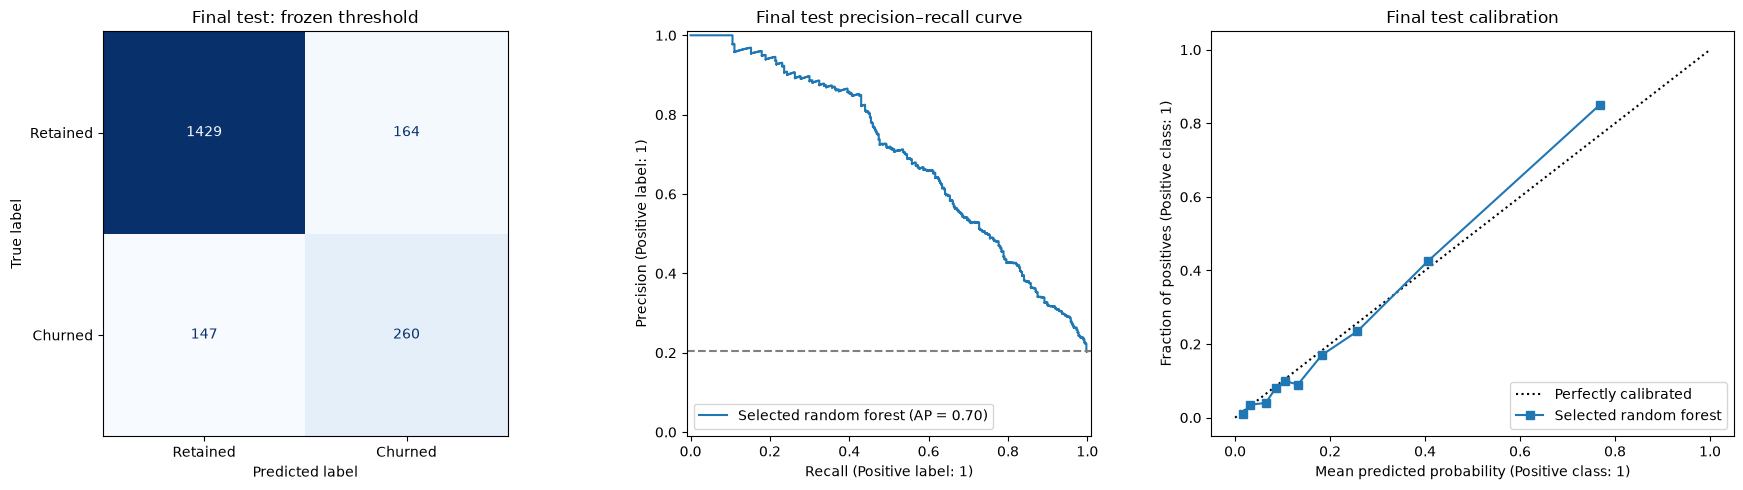

In [126]:
final_test_fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Retained", "Churned"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Final test: frozen threshold")

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Selected random forest",
    ax=axes[1],
)
axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="grey",
)
axes[1].set_title("Final test precision–recall curve")

CalibrationDisplay.from_predictions(
    y_test,
    test_probabilities,
    n_bins=10,
    strategy="quantile",
    name="Selected random forest",
    ax=axes[2],
)
axes[2].set_title("Final test calibration")

final_test_fig.tight_layout()
plt.show()

A random forest selected through training cross-validation achieved test ROC-AUC of 0.857 and average precision of 0.698. At a threshold selected on validation data to maximise F1, it identified 63.9% of churners with 61.3% precision, flagging 21.2% of test customers. Validation diagnostics revealed weak detection among younger customers and variation across subgroups. Results apply to this held-out dataset; temporal generalisation and retention intervention value remain unverified.

In [127]:
with mlflow.start_run(run_id=final_run_id):
    mlflow.log_metrics({
        f"test_{name}": float(value)
        for name, value in final_test_metrics.items()
    })

    mlflow.log_param("test_rows", len(y_test))

    mlflow.log_figure(
        final_test_fig,
        "plots/final_test_evaluation.png",
    )

    mlflow.log_dict(
        {
            "labels": [0, 1],
            "rows": "actual",
            "columns": "predicted",
            "matrix": [
                [int(tn), int(fp)],
                [int(fn), int(tp)],
            ],
        },
        "test_confusion_matrix.json",
    )

    with tempfile.TemporaryDirectory() as temporary_directory:
        results_path = (
            Path(temporary_directory) / "final_test_metrics.csv"
        )

        pd.Series(final_test_metrics).rename(
            "test_result"
        ).to_csv(results_path)

        mlflow.log_artifact(str(results_path))

    mlflow.set_tag("test_set_evaluated", "true")

print("Final test evaluation recorded.")

Final test evaluation recorded.
